# ABSA Genshin Impact — REPLIKASI Penelitian Terdahulu (CountVectorizer)

**Aspect-Based Sentiment Analysis (ABSA)** pada ulasan game Genshin Impact — *replikasi protokol penelitian terdahulu*.

| Komponen | Detail |
|---|---|
| **Preprocessing** | 7 tahap (Case Folding → Cleansing → Normalisasi → Tokenizing → Convert Negasi → Stopword Removal → Stemming) |
| **Ekstraksi Fitur** | **CountVectorizer** (Bag-of-Words), di-*fit* pada seluruh korpus tiap aspek |
| **Balancing** | 4 skenario: None · SMOTE · Tomek · SMOTE-Tomek |
| **Protokol** | **Balancing DULU → K-Fold SESUDAHNYA** (sesuai alur penelitian terdahulu) |
| **Algoritma** | Multinomial Naive Bayes |
| **Aspek** | Gameplay & Storyline · Aksesibilitas · Grafis & Performa · Fitur · Others |
| **Evaluasi** | 10-Fold Cross-Validation — hasil **saat training** dan **saat evaluasi** ditampilkan berdampingan |

Setiap tahap preprocessing menyimpan hasil ke CSV dan menampilkan preview.

---

### Perbedaan dengan notebook utama (skenario 1–4)

| | Notebook utama | Notebook replikasi ini |
|---|---|---|
| Urutan proses | Split K-Fold → CountVectorizer *fit* pada fold latih → balancing di dalam fold | **CountVectorizer *fit* pada seluruh data → balancing pada seluruh data → baru dibagi K-Fold** |
| Metrik yang dilaporkan | Hanya hasil validasi | **Hasil training DAN hasil evaluasi** (+ selisih/gap) |
| Metode balancing | none · SMOTE · Tomek · SMOTE-Tomek |

## 1. Setup & Import

In [ ]:
!pip install --upgrade pip
!pip install  scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 25.6 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


In [ ]:
!pip install -U imbalanced-learn
!pip install Sastrawi


In [ ]:
import re
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import sparse

import nltk
from nltk.corpus import stopwords as nltk_stopwords

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import TomekLinks, RandomUnderSampler
from imblearn.combine import SMOTETomek

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 100

# Download required NLTK resource if missing
try:
    nltk_stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)

print("[OK] Semua library berhasil diimport")
print(f"     scikit-learn : {sklearn.__version__}")


[OK] Semua library berhasil diimport
     scikit-learn : 1.6.1



## 2. Konfigurasi Global

In [ ]:
# ============================================================
# KONFIGURASI - ubah sesuai kebutuhan
# ============================================================
import urllib.request
import io

OUTPUT_DIR = Path('.').resolve() / 'output_replikasi'
OUTPUT_DIR.mkdir(exist_ok=True)

# -- URL Google Drive -----------------------------------------
GDRIVE_URLS = {
    'default'      : 'https://drive.google.com/uc?id=1eCcy5ehR-UrMN9YA6bDyz5qSOtnZT8Ry',
    'explore'      : 'https://drive.google.com/uc?id=1wzFt7d9gnP09HndCfRO8gio1sGJvhmx_',
    'explorev2'    : 'https://drive.google.com/uc?id=1rd3-uMBFIukwbNuHKCPnzOAEJ01OhUtE',
    'explorev3'    : 'https://drive.google.com/uc?id=1qMcVJGSONAJPEKXPUZxbKD6V9REBMt6P',
    'normalization': 'https://drive.google.com/uc?id=/1j3e8MccRnYDbZYAWnEhJKUs-RJZnYtsb',
    'stopwords'    : 'https://drive.google.com/uc?id=1MwAeBTKiRxCuQCJVLjsmJ8NEXq2btlQ4',
}

# dataset: 'default' (dataset_final.csv) | 'explore' (3000 data)
DATASET_CHOICE = 'explore'
DATASET_URL    = GDRIVE_URLS[DATASET_CHOICE]

# -- PROTOKOL EVALUASI ----------------------------------------
# 'balance_then_kfold' : balancing pada seluruh data, K-Fold SETELAH balancing  (REPLIKASI)
# 'kfold_then_balance' : K-Fold dulu, balancing hanya di fold latih             (pembanding)
CV_PROTOCOL = 'balance_then_kfold'

# Preprocessing toggles (True = aktif)
PREPROCESS_CONFIG = {
    'case_folding'    : True,
    'cleansing'       : True,
    'normalization'   : True,
    'tokenizing'      : True,
    'convert_negasi'  : True,
    'stopword_removal': True,
    'stemming'        : True,
}

# CountVectorizer (Bag-of-Words) config
COUNTVEC_CONFIG = {
    'analyzer'   : 'word',
    'min_df'     : 2,
    'max_df'     : 0.95,
    'ngram_min'  : 1,
    'ngram_max'  : 2,
    'alpha'      : 1.0,
    'chi2_k'     : None,
}

K_FOLDS      = 10   # jumlah fold cross-validation (Stratified K-Fold)
RANDOM_STATE = 42
PREVIEW_N    = 5    # jumlah baris yang ditampilkan setiap preview

# Filtering processed text
MIN_TOKEN_BASIS = 'processed' # 'processed' atau 'content'
MIN_TOKEN       = 1           # Jumlah kata minimal setelah preprocessing

# Aspek
BASE_ASPECTS = ['gs', 'a', 'gp', 'f']
ASPECTS      = BASE_ASPECTS + ['others']
ASPECT_LABELS = {
    'gs'    : 'Gameplay & Storyline',
    'a'     : 'Aksesibilitas',
    'gp'    : 'Grafis & Performa',
    'f'     : 'Fitur',
    'others': 'Others',
}
SENTIMENT_LABELS = {-1: 'Negatif', 1: 'Positif'}

# Metode balancing (ROS & RUS = metode penelitian terdahulu)
BALANCE_METHODS = ['none', 'smote', 'tomek', 'smote_tomek']
BALANCE_LABELS  = {
    'none'       : 'Tanpa Balancing',
    'smote'      : 'SMOTE',
    'tomek'      : 'Tomek Links',
    'smote_tomek': 'SMOTE-Tomek',
}

# Kata kunci aspek (untuk prediksi)
ASPECT_KEYWORDS = {
    'gs': ['gameplay', 'stori', 'story', 'storyline', 'aether', 'lumine', 'lore', 'konsep',
           'cerita', 'elemental', 'reaction', 'reaksi', 'elemen', 'element', 'mondstadt',
           'liyue', 'inazuma', 'game', 'gamenya', 'storynya', 'storinya', 'ceritanya'],
    'a': ['mouse', 'keyboard', 'joystick', 'controller', 'server', 'login', 'connection',
          'koneksi', 'internet', 'download', 'update', 'pembaruan', 'akun', 'google',
          'unduh', 'playstore', 'jaringan', 'gamepad', 'kontroler', 'platform', 'bug',
          'versi', 'size', 'kuota', 'sinyal', 'ukuran', 'gb', 'bugnya', 'ping'],
    'gp': ['low', 'medium', 'high', 'lag', 'graphic', 'grafik', 'grafis', 'snapdragon',
           'iphone', 'samsung', 'xiaomi', 'redmi', 'oppo', 'vivo', 'advan', 'madiatek',
           'exynos', 'pocophone', 'blackshark', 'rog', 'legion', 'freeze', 'kentang',
           'ubi', 'ringan', 'berat', 'drop', 'framedrop', 'ram', 'realistis', 'hp',
           'smartphone', 'fps', 'frame', 'loading', 'load', 'grafisnya', 'grafiknya'],
    'f': ['senjata', 'artifak', 'artifact', 'artefak', 'gacha', 'karakter', 'banner',
          'map', 'mora', 'primogem', 'genesis crystal', 'material', 'topup', 'bayar',
          'tombol', 'quest', 'wish', 'resin', 'friend', 'teman', 'serenitea', 'event',
          'lagu', 'musik', 'music', 'sound', 'sountrack', 'gachanya', 'questnya',
          'resinnya', 'musiknya', 'sountracknya', 'co-op', 'coop', 'multiplayer'],
    'others': [],
}

print('[OK] Konfigurasi dimuat')
print(f'  Dataset  : {DATASET_CHOICE} -> {DATASET_URL}')
print(f'  Output   : {OUTPUT_DIR}')
print(f'  Protokol : {CV_PROTOCOL}  (balancing dulu, K-Fold sesudahnya)')
print(f'  Balancing: {BALANCE_METHODS}')

[OK] Konfigurasi dimuat
  Dataset  : explore -> https://drive.google.com/uc?id=1wzFt7d9gnP09HndCfRO8gio1sGJvhmx_
  Output   : /content/output_replikasi
  Protokol : balance_then_kfold  (balancing dulu, K-Fold sesudahnya)
  Balancing: ['none', 'smote', 'tomek', 'smote_tomek']



## 3. Fungsi Helper Preprocessing

In [ ]:
# --------------------------------------------------
# Kamus & konstanta preprocessing
# --------------------------------------------------
NEGATION_WORDS = {'tidak','bukan','jangan','belum','tak','ga','gak','kagak','ngga','nggak'}

EMOJI_MAP = {
    '😊':' senang ','😄':' senang ','😁':' senang ','🙂':' senang ','😀':' senang ',
    '😍':' suka ','🥰':' suka ',
    '❤':' cinta ','❤️':' cinta ','💕':' cinta ','💖':' cinta ',
    '👍':' bagus ','👌':' bagus ','💯':' bagus ',
    '👎':' buruk ','😞':' sedih ','😢':' sedih ','😭':' sedih ','🥲':' sedih ',
    '😡':' marah ','🤬':' marah ','😤':' marah ','😠':' marah ',
    '🔥':' keren ','✨':' keren ','💪':' keren ',
    '😂':' lucu ','🤣':' lucu ',
    '😴':' bosan ','🙄':' kesal ','😒':' kesal ',
    '⭐':' bintang ','🌟':' bintang ',
}

SLANG_DICT = {
    'yg':'yang','dgn':'dengan','krn':'karena','tdk':'tidak',
    'tp':'tapi','trs':'terus','udh':'sudah','blm':'belum',
    'bgt':'banget','gw':'saya','gue':'saya','lu':'kamu',
    'lo':'kamu','klo':'kalau','kalo':'kalau','ngga':'tidak',
    'gak':'tidak','ga':'tidak','mantul':'mantap','mantap':'bagus',
    'keren':'bagus','asik':'menyenangkan','asyik':'menyenangkan',
}

EN_ID_DICT = {
    'good':'bagus','great':'bagus','nice':'bagus','awesome':'keren',
    'amazing':'menakjubkan','love':'suka','like':'suka','best':'terbaik',
    'fun':'seru','cool':'keren','beautiful':'indah','perfect':'sempurna',
    'wonderful':'menakjubkan','excellent':'sempurna','fantastic':'fantastis',
    'bad':'buruk','worst':'terburuk','boring':'membosankan',
    'hate':'benci','terrible':'buruk','horrible':'mengerikan',
    'poor':'buruk','lag':'lag','laggy':'lemot','slow':'lambat',
    'graphic':'grafik','graphics':'grafik','sound':'suara','music':'musik',
    'story':'cerita','character':'karakter','characters':'karakter',
    'gameplay':'gameplay','feature':'fitur','features':'fitur',
    'update':'update','bug':'bug','error':'error','crash':'crash',
    'thanks':'terima kasih','please':'tolong',
    'yes':'iya','no':'tidak','very':'sangat','really':'sangat',
    'but':'tapi','and':'dan','or':'atau','the':'','is':'',
}

# --------------------------------------------------
# Lazy loaders
# --------------------------------------------------
_stemmer       = None
_stopwords_set = None
_slang_ext     = None

def get_stemmer():
    global _stemmer
    if _stemmer is None:
        print('  [..] Memuat Sastrawi Stemmer...')
        _stemmer = StemmerFactory().create_stemmer()
        print('  [OK] Stemmer siap')
    return _stemmer

def get_stopwords() -> set:
    global _stopwords_set
    if _stopwords_set is not None:
        return _stopwords_set
    sastra = set(StopWordRemoverFactory().get_stop_words())
    eng    = set(nltk_stopwords.words('english'))
    custom = set()
    try:
        resp = urllib.request.urlopen(GDRIVE_URLS['stopwords'])
        custom = set(resp.read().decode('utf-8').split())
        print('  [OK] stopword.txt dimuat dari Google Drive')
    except Exception as e:
        print(f'  [!] Gagal memuat stopword.txt: {e}')
    _stopwords_set = sastra | eng | custom
    return _stopwords_set

def get_slang_ext() -> dict:
    global _slang_ext
    if _slang_ext is not None:
        return _slang_ext
    d = {}
    try:
        df_n = pd.read_csv(GDRIVE_URLS['normalization'], header=None, names=['slang','baku'])
        for _, row in df_n.iterrows():
            s, b = str(row['slang']).strip().lower(), str(row['baku']).strip().lower()
            if s and b and s != 'nan':
                d[s] = b
        print(f'  [OK] normalization.csv dimuat dari Google Drive ({len(d)} entri)')
    except Exception as e:
        print(f'  [!] Gagal memuat normalization.csv: {e}')
    _slang_ext = d
    return d

# --------------------------------------------------
# Fungsi tiap tahap preprocessing
# --------------------------------------------------
def step_case_folding(text: str) -> str:
    return text.lower()

def step_cleansing(text: str) -> str:
    for emo, word in EMOJI_MAP.items():
        if emo in text:
            text = text.replace(emo, word)
    text = re.sub(r'([a-zA-Z])\1{2,}', r'\1', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+|#\w+', ' ', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def step_normalization(text: str) -> str:
    external = get_slang_ext()
    tokens   = text.split()
    out = []
    for t in tokens:
        if t in SLANG_DICT:
            out.append(SLANG_DICT[t])
        elif t in external:
            out.append(external[t])
        elif t in EN_ID_DICT:
            mapped = EN_ID_DICT[t]
            if mapped: out.append(mapped)
        else:
            out.append(t)
    return ' '.join(out).strip()

def step_tokenizing(text: str) -> list:
    return text.split()

def step_convert_negasi(tokens: list) -> list:
    out, skip = [], False
    for i, tok in enumerate(tokens):
        if skip:
            skip = False; continue
        if tok in NEGATION_WORDS and i + 1 < len(tokens):
            out.append(f'{tok}_{tokens[i+1]}')
            skip = True
        else:
            out.append(tok)
    return out

def step_stopword_removal(tokens: list) -> list:
    sw = get_stopwords()
    return [t for t in tokens if ('_' in t) or (t not in sw)]

def step_stemming(tokens: list) -> list:
    stemmer = get_stemmer()
    out = []
    for tok in tokens:
        if '_' in tok:
            parts = tok.split('_')
            out.append('_'.join(stemmer.stem(p) if p else p for p in parts))
        else:
            out.append(stemmer.stem(tok))
    return out

print('[OK] Semua fungsi preprocessing didefinisikan')


[OK] Semua fungsi preprocessing didefinisikan



## 4. Load Dataset

In [ ]:
def load_dataset(path) -> pd.DataFrame:
    df = pd.read_csv(path)
    for a in BASE_ASPECTS:
        if f'aspek_{a}' not in df.columns and f'label_{a}' in df.columns:
            df[f'aspek_{a}'] = (df[f'label_{a}'] != 0).astype(int)
    if 'aspek_others' not in df.columns:
        cond = (df['aspek_gs']==0)&(df['aspek_a']==0)&(df['aspek_gp']==0)&(df['aspek_f']==0)
        df['aspek_others'] = cond.astype(int)
    if 'label_others' not in df.columns:
        # Modified: Assign 0 if not an 'others' aspect, otherwise default to 1 (positive)
        df['label_others'] = df['aspek_others'].apply(lambda x: 1 if int(x)==1 else -1)
    df['content'] = df['content'].fillna('').astype(str)
    return df

print(f'Memuat dataset: {DATASET_CHOICE} dari Google Drive ...')
df_raw = load_dataset(DATASET_URL)
print(f'[OK] Dataset dimuat: {len(df_raw)} ulasan, {len(df_raw.columns)} kolom')
print()

# Salinan kerja; kolom 'text' adalah yang akan diproses
df = df_raw.copy()
df['text'] = df['content']

# Ringkasan distribusi
print('=== Distribusi Label per Aspek ===')
print('(1 = Positif, -1 = Negatif, 0 = aspek tidak disebut -> TIDAK dilatih)')
summary_rows = []
for a in ASPECTS:
    col = df.get(f'label_{a}')
    if col is None: continue
    pos, neg = int((col == 1).sum()), int((col == -1).sum())
    summary_rows.append({
        'Aspek'          : ASPECT_LABELS[a],
        'Positif'        : pos,
        'Negatif'        : neg,
        'Tidak Disebut'  : int((col == 0).sum()),
        'Total Disebut'  : pos + neg,
        'Imbalance Ratio': round(max(pos, neg) / min(pos, neg), 2) if min(pos, neg) else None,
    })
df_summary = pd.DataFrame(summary_rows)
display(df_summary)

print('\n=== Preview Dataset Mentah (5 baris pertama) ===')
display(df[['content'] + [f'label_{a}' for a in ASPECTS if f'label_{a}' in df.columns]].head(PREVIEW_N))

Memuat dataset: explore dari Google Drive ...
[OK] Dataset dimuat: 3054 ulasan, 14 kolom

=== Distribusi Label per Aspek ===
(1 = Positif, -1 = Negatif, 0 = aspek tidak disebut -> TIDAK dilatih)


,Aspek,Positif,Negatif,Tidak Disebut,Total Disebut,Imbalance Ratio
0,Gameplay & Storyline,1001,162,1891,1163,6.18
1,Aksesibilitas,311,151,2592,462,2.06
2,Grafis & Performa,577,213,2264,790,2.71
3,Fitur,292,100,2662,392,2.92
4,Others,1299,1755,0,3054,1.35



=== Preview Dataset Mentah (5 baris pertama) ===


,content,label_gs,label_a,label_gp,label_f,label_others
0,Lebih bagus dibanding game lain walaupun kadan...,1,0,0,1,-1
1,finally ayaka banner.....,0,0,0,1,-1
2,"Game ini saya suka alurnya, konsepnya,serta ba...",1,0,0,0,-1
3,"Ok,",0,0,0,0,1
4,"Beautiful, fun, and this is the best MMORPG game",1,0,0,0,-1


## 5. Praproses


### Tahap 1: Case Folding
Mengubah semua huruf menjadi huruf kecil (*lowercase*).

In [ ]:
t0 = time.time()

df['step1_case_folding'] = df['text'].apply(step_case_folding)

elapsed = time.time() - t0
print(f'[OK] Tahap 1 (Case Folding) selesai dalam {elapsed:.2f}s')

out_path = OUTPUT_DIR / 'step1_case_folding.csv'
df[['content', 'step1_case_folding']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

print(f'\n=== Preview Tahap 1: Case Folding ===')
preview = df[['content', 'step1_case_folding']].head(PREVIEW_N).copy()
preview.columns = ['Original', 'Case Folding']
display(preview)

df['text'] = df['step1_case_folding']


[OK] Tahap 1 (Case Folding) selesai dalam 0.00s
  -> Disimpan: /content/output_replikasi/step1_case_folding.csv

=== Preview Tahap 1: Case Folding ===


,Original,Case Folding
0,Lebih bagus dibanding game lain walaupun kadan...,lebih bagus dibanding game lain walaupun kadan...
1,finally ayaka banner.....,finally ayaka banner.....
2,"Game ini saya suka alurnya, konsepnya,serta ba...","game ini saya suka alurnya, konsepnya,serta ba..."
3,"Ok,","ok,"
4,"Beautiful, fun, and this is the best MMORPG game","beautiful, fun, and this is the best mmorpg game"



### Tahap 2: Cleansing
- Konversi emoji ke kata sentimen
- Hapus URL, mention, hashtag
- Hapus karakter berulang (`baguuus` -> `bagus`)
- Hapus angka dan tanda baca

In [ ]:
t0 = time.time()

df['step2_cleansing'] = df['text'].apply(step_cleansing)

elapsed = time.time() - t0
print(f'[OK] Tahap 2 (Cleansing) selesai dalam {elapsed:.2f}s')

out_path = OUTPUT_DIR / 'step2_cleansing.csv'
df[['content', 'step1_case_folding', 'step2_cleansing']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

print(f'\n=== Preview Tahap 2: Cleansing ===')
preview = df[['step1_case_folding', 'step2_cleansing']].head(PREVIEW_N).copy()
preview.columns = ['Sebelum (Case Folding)', 'Sesudah (Cleansing)']
display(preview)

df['text'] = df['step2_cleansing']


[OK] Tahap 2 (Cleansing) selesai dalam 0.07s
  -> Disimpan: /content/output_replikasi/step2_cleansing.csv

=== Preview Tahap 2: Cleansing ===


,Sebelum (Case Folding),Sesudah (Cleansing)
0,lebih bagus dibanding game lain walaupun kadan...,lebih bagus dibanding game lain walaupun kadan...
1,finally ayaka banner.....,finally ayaka banner
2,"game ini saya suka alurnya, konsepnya,serta ba...",game ini saya suka alurnya konsepnya serta bac...
3,"ok,",ok
4,"beautiful, fun, and this is the best mmorpg game",beautiful fun and this is the best mmorpg game



### Tahap 3: Normalisasi
- Normalisasi slang Indonesia (`gak` -> `tidak`, `bgt` -> `banget`)
- Terjemahan kata Inggris -> Indonesia
- Kamus normalisasi eksternal (`normalization.csv`)

In [ ]:
t0 = time.time()

ext_dict = get_slang_ext()
print(f'  Kamus eksternal: {len(ext_dict)} entri')

df['step3_normalization'] = df['text'].apply(step_normalization)

elapsed = time.time() - t0
print(f'[OK] Tahap 3 (Normalisasi) selesai dalam {elapsed:.2f}s')

out_path = OUTPUT_DIR / 'step3_normalization.csv'
df[['content', 'step2_cleansing', 'step3_normalization']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

print(f'\n=== Preview Tahap 3: Normalisasi ===')
preview = df[['step2_cleansing', 'step3_normalization']].head(PREVIEW_N).copy()
preview.columns = ['Sebelum (Cleansing)', 'Sesudah (Normalisasi)']
display(preview)

df['text'] = df['step3_normalization']


  [!] Gagal memuat normalization.csv: HTTP Error 404: Not Found
  Kamus eksternal: 0 entri
[OK] Tahap 3 (Normalisasi) selesai dalam 0.04s
  -> Disimpan: /content/output_replikasi/step3_normalization.csv

=== Preview Tahap 3: Normalisasi ===


,Sebelum (Cleansing),Sesudah (Normalisasi)
0,lebih bagus dibanding game lain walaupun kadan...,lebih bagus dibanding game lain walaupun kadan...
1,finally ayaka banner,finally ayaka banner
2,game ini saya suka alurnya konsepnya serta bac...,game ini saya suka alurnya konsepnya serta bac...
3,ok,ok
4,beautiful fun and this is the best mmorpg game,indah seru dan this terbaik mmorpg game



### Tahap 4: Tokenizing
Memecah kalimat menjadi daftar kata (*token*).

In [ ]:
t0 = time.time()

df['step4_tokens'] = df['text'].apply(step_tokenizing)

elapsed = time.time() - t0
print(f'[OK] Tahap 4 (Tokenizing) selesai dalam {elapsed:.2f}s')

df['step4_tokens_str'] = df['step4_tokens'].apply(lambda x: str(x))
out_path = OUTPUT_DIR / 'step4_tokenizing.csv'
df[['content', 'step3_normalization', 'step4_tokens_str']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

token_counts = df['step4_tokens'].apply(len)
print(f'  Rata-rata token per ulasan : {token_counts.mean():.1f}')
print(f'  Maks token                 : {token_counts.max()}')
print(f'  Min token                  : {token_counts.min()}')

print(f'\n=== Preview Tahap 4: Tokenizing ===')
preview = pd.DataFrame({
    'Sebelum (Normalisasi)': df['step3_normalization'].head(PREVIEW_N),
    'Token (List)': df['step4_tokens'].head(PREVIEW_N),
    'Jumlah Token': token_counts.head(PREVIEW_N),
})
display(preview)


[OK] Tahap 4 (Tokenizing) selesai dalam 0.01s
  -> Disimpan: /content/output_replikasi/step4_tokenizing.csv
  Rata-rata token per ulasan : 10.7
  Maks token                 : 97
  Min token                  : 0

=== Preview Tahap 4: Tokenizing ===


,Sebelum (Normalisasi),Token (List),Jumlah Token
0,lebih bagus dibanding game lain walaupun kadan...,"[lebih, bagus, dibanding, game, lain, walaupun...",13
1,finally ayaka banner,"[finally, ayaka, banner]",3
2,game ini saya suka alurnya konsepnya serta bac...,"[game, ini, saya, suka, alurnya, konsepnya, se...",57
3,ok,[ok],1
4,indah seru dan this terbaik mmorpg game,"[indah, seru, dan, this, terbaik, mmorpg, game]",7


### Tahap 5: Convert Negasi
Menggabungkan kata negasi dengan kata berikutnya:
`tidak bagus` -> `tidak_bagus` (agar tidak dianggap stopword terpisah)

In [ ]:
t0 = time.time()

df['step5_negasi'] = df['step4_tokens'].apply(step_convert_negasi)

elapsed = time.time() - t0
print(f'[OK] Tahap 5 (Convert Negasi) selesai dalam {elapsed:.2f}s')

df['step5_negasi_str'] = df['step5_negasi'].apply(lambda x: str(x))
out_path = OUTPUT_DIR / 'step5_convert_negasi.csv'
df[['content', 'step4_tokens_str', 'step5_negasi_str']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

mask_has_neg = df['step5_negasi_str'].str.contains('_', na=False)
print(f'  Ulasan dengan negasi terdeteksi: {mask_has_neg.sum()}')

print(f'\n=== Preview Tahap 5: Convert Negasi ===')
preview = pd.DataFrame({
    'Token (Sebelum)': df['step4_tokens'].head(PREVIEW_N),
    'Token (Setelah Negasi)': df['step5_negasi'].head(PREVIEW_N),
})
display(preview)

print('\n=== Contoh Ulasan dengan Negasi ===')
neg_examples = df[mask_has_neg][['content', 'step5_negasi']].head(3)
if len(neg_examples) > 0:
    for _, row in neg_examples.iterrows():
        neg_tokens = [t for t in row['step5_negasi'] if '_' in t]
        print(f'  Ulasan  : {row["content"][:80]}...')
        print(f'  Negasi  : {neg_tokens}')
        print()


[OK] Tahap 5 (Convert Negasi) selesai dalam 0.01s
  -> Disimpan: /content/output_replikasi/step5_convert_negasi.csv
  Ulasan dengan negasi terdeteksi: 469

=== Preview Tahap 5: Convert Negasi ===


,Token (Sebelum),Token (Setelah Negasi)
0,"[lebih, bagus, dibanding, game, lain, walaupun...","[lebih, bagus, dibanding, game, lain, walaupun..."
1,"[finally, ayaka, banner]","[finally, ayaka, banner]"
2,"[game, ini, saya, suka, alurnya, konsepnya, se...","[game, ini, saya, suka, alurnya, konsepnya, se..."
3,[ok],[ok]
4,"[indah, seru, dan, this, terbaik, mmorpg, game]","[indah, seru, dan, this, terbaik, mmorpg, game]"



=== Contoh Ulasan dengan Negasi ===
  Ulasan  : Game ini saya suka alurnya, konsepnya,serta background latar nya juga suka awaln...
  Negasi  : ['tidak_membuat']

  Ulasan  : Sudah ku update kenapa masih harus konfirmasi update terbaru di temukan,, bahkan...
  Negasi  : ['tidak_bisa']

  Ulasan  : Suka banget ama ini game, ga ada tuh yang namanya bosen main...yang paling menar...
  Negasi  : ['tidak_ada']



### Tahap 6: Stopword Removal
Menghapus kata-kata umum yang tidak mengandung makna sentimen.
Sumber: Sastrawi + NLTK English + `stopword.txt` (kustom)

> **Catatan:** Token negasi (mengandung `_`) **dilindungi** dari penghapusan.

In [ ]:
t0 = time.time()

sw = get_stopwords()
print(f'  Total stopword: {len(sw)}')

df['step6_no_stopword'] = df['step5_negasi'].apply(step_stopword_removal)

elapsed = time.time() - t0
print(f'[OK] Tahap 6 (Stopword Removal) selesai dalam {elapsed:.2f}s')

df['step6_no_stopword_str'] = df['step6_no_stopword'].apply(lambda x: str(x))
out_path = OUTPUT_DIR / 'step6_stopword_removal.csv'
df[['content', 'step5_negasi_str', 'step6_no_stopword_str']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

before_count = df['step5_negasi'].apply(len)
after_count  = df['step6_no_stopword'].apply(len)
reduction    = ((before_count - after_count) / before_count.replace(0, 1) * 100)
print(f'  Rata-rata token sebelum: {before_count.mean():.1f}')
print(f'  Rata-rata token sesudah: {after_count.mean():.1f}')
print(f'  Rata-rata reduksi      : {reduction.mean():.1f}%')

print(f'\n=== Preview Tahap 6: Stopword Removal ===')
preview = pd.DataFrame({
    'Token Sebelum': df['step5_negasi'].head(PREVIEW_N),
    'Token Sesudah': df['step6_no_stopword'].head(PREVIEW_N),
})
display(preview)


  [OK] stopword.txt dimuat dari Google Drive
  Total stopword: 2808
[OK] Tahap 6 (Stopword Removal) selesai dalam 1.51s
  -> Disimpan: /content/output_replikasi/step6_stopword_removal.csv
  Rata-rata token sebelum: 10.5
  Rata-rata token sesudah: 4.4
  Rata-rata reduksi      : 49.0%

=== Preview Tahap 6: Stopword Removal ===


,Token Sebelum,Token Sesudah
0,"[lebih, bagus, dibanding, game, lain, walaupun...","[bagus, dibanding, kadang, ngeselin, ngegacha,..."
1,"[finally, ayaka, banner]","[finally, banner]"
2,"[game, ini, saya, suka, alurnya, konsepnya, se...","[suka, alurnya, konsepnya, background, latar, ..."
3,[ok],[]
4,"[indah, seru, dan, this, terbaik, mmorpg, game]","[indah, seru]"


### Tahap 7: Stemming
Mengubah kata ke bentuk dasar menggunakan **Sastrawi** (Bahasa Indonesia).

> **Catatan:** Ini tahap paling lambat. Token negasi dipecah, di-stem per komponen, lalu digabung ulang.

In [ ]:
print('[..] Memulai stemming (proses ini membutuhkan beberapa menit)...')
t0 = time.time()

stemmer = get_stemmer()

results_stem = []
total = len(df)
for i, tokens in enumerate(df['step6_no_stopword'], 1):
    results_stem.append(step_stemming(tokens))
    if i % 500 == 0 or i == total:
        print(f'  Progress: {i}/{total} ({i/total*100:.1f}%)')

df['step7_stemmed'] = results_stem

elapsed = time.time() - t0
print(f'[OK] Tahap 7 (Stemming) selesai dalam {elapsed:.1f}s')

df['processed'] = df['step7_stemmed'].apply(lambda x: ' '.join(x))

df['step7_stemmed_str'] = df['step7_stemmed'].apply(lambda x: str(x))
out_path = OUTPUT_DIR / 'step7_stemming.csv'
df[['content', 'step6_no_stopword_str', 'step7_stemmed_str', 'processed']].to_csv(out_path, index=False, encoding='utf-8')
print(f'  -> Disimpan: {out_path}')

print(f'\n=== Preview Tahap 7: Stemming ===')
preview = pd.DataFrame({
    'Token Sebelum Stemming': df['step6_no_stopword'].head(PREVIEW_N),
    'Token Sesudah Stemming': df['step7_stemmed'].head(PREVIEW_N),
    'Hasil Akhir (String)': df['processed'].head(PREVIEW_N),
})
display(preview)


[..] Memulai stemming (proses ini membutuhkan beberapa menit)...
  [..] Memuat Sastrawi Stemmer...
  [OK] Stemmer siap
  Progress: 500/3054 (16.4%)
  Progress: 1000/3054 (32.7%)
  Progress: 1500/3054 (49.1%)
  Progress: 2000/3054 (65.5%)
  Progress: 2500/3054 (81.9%)
  Progress: 3000/3054 (98.2%)
  Progress: 3054/3054 (100.0%)
[OK] Tahap 7 (Stemming) selesai dalam 288.4s
  -> Disimpan: /content/output_replikasi/step7_stemming.csv

=== Preview Tahap 7: Stemming ===


,Token Sebelum Stemming,Token Sesudah Stemming,Hasil Akhir (String)
0,"[bagus, dibanding, kadang, ngeselin, ngegacha,...","[bagus, banding, kadang, ngeselin, ngegacha, s...",bagus banding kadang ngeselin ngegacha senjata
1,"[finally, banner]","[finally, banner]",finally banner
2,"[suka, alurnya, konsepnya, background, latar, ...","[suka, alur, konsep, background, latar, suka, ...",suka alur konsep background latar suka tidak_b...
3,[],[],
4,"[indah, seru]","[indah, seru]",indah seru


In [ ]:
# Bersihkan baris dengan hasil preprocessing kosong
before_n = len(df) # Renamed to avoid confusion with `before` used as a count


df['processed'] = df['processed'].fillna('').astype(str).str.strip()
df = df[df['processed'] != '']
df = df[df['processed'].str.split().str.len() >= 1]   # ganti >=1 jadi >=2 kalau mau lebih ketat
df = df.reset_index(drop=True)

basis_teks = (df['processed'] if MIN_TOKEN_BASIS == 'processed'
              else df['processed'].fillna('').astype(str))
df['n_kata'] = basis_teks.str.split().str.len()

mask_kosong = df['processed'] == ''
mask_pendek = ((df['n_kata'] < MIN_TOKEN) & ~mask_kosong if MIN_TOKEN > 1
               else pd.Series(False, index=df.index))
mask_buang  = mask_kosong | mask_pendek

dibuang = df.loc[mask_buang].copy()
if len(dibuang):
    dibuang['alasan'] = np.where(mask_kosong[mask_buang], 'kosong setelah praproses', f'< {MIN_TOKEN} kata')
    dibuang[['processed', 'n_kata', 'alasan']].to_csv(OUTPUT_DIR / 'dibuang_ulasan_pendek.csv', index=False, encoding='utf-8-sig')

df = df.loc[~mask_buang].reset_index(drop=True)

print(f'\n\u2713 Praproses selesai dalam {time.time()-t0:.1f}s')
print(f'  Total dibuang / sisa        : {before_n - len(df)} / {len(df)} ulasan')


print(f'Dibuang {before_n - len(df)} baris kosong. Sisa: {len(df)} baris')



✓ Praproses selesai dalam 288.5s
  Total dibuang / sisa        : 261 / 2793 ulasan
Dibuang 261 baris kosong. Sisa: 2793 baris


### Simpan Hasil Preprocessing Lengkap
Semua 7 tahap dalam satu file CSV komprehensif.

In [ ]:
label_cols = [f'label_{a}' for a in ASPECTS if f'label_{a}' in df.columns]
aspek_cols = [f'aspek_{a}' for a in ASPECTS if f'aspek_{a}' in df.columns]

cols_to_save = (
    ['content']
    + label_cols
    + aspek_cols
    + [
        'step1_case_folding',
        'step2_cleansing',
        'step3_normalization',
        'step4_tokens_str',
        'step5_negasi_str',
        'step6_no_stopword_str',
        'step7_stemmed_str',
        'processed',
    ]
)

out_path = OUTPUT_DIR / 'preprocessing_all_steps.csv'
df[cols_to_save].to_csv(out_path, index=False, encoding='utf-8')
print(f'[OK] Semua tahap preprocessing disimpan: {out_path}')
print(f'  Ukuran file  : {out_path.stat().st_size / 1024:.1f} KB')
print(f'  Jumlah baris : {len(df)}')
print(f'  Jumlah kolom : {len(cols_to_save)}')

print('\n=== Rekap Perubahan dari Original -> Processed ===')
sample = df[['content', 'processed']].head(PREVIEW_N).copy()
sample.columns = ['Ulasan Asli', 'Hasil Preprocessing']
display(sample)


[OK] Semua tahap preprocessing disimpan: /content/output_replikasi/preprocessing_all_steps.csv
  Ukuran file  : 1752.5 KB
  Jumlah baris : 2793
  Jumlah kolom : 19

=== Rekap Perubahan dari Original -> Processed ===


,Ulasan Asli,Hasil Preprocessing
0,Lebih bagus dibanding game lain walaupun kadan...,bagus banding kadang ngeselin ngegacha senjata
1,finally ayaka banner.....,finally banner
2,"Game ini saya suka alurnya, konsepnya,serta ba...",suka alur konsep background latar suka tidak_b...
3,"Beautiful, fun, and this is the best MMORPG game",indah seru
4,update yang bagus apalagi map terbaru inazuma ...,update bagus map baru nomer dunia


## 6. Ekstraksi Fitur: Count Vectorization (Bag-of-Words)

Mengubah teks ke vektor fitur numerik menggunakan **CountVectorizer** — setiap fitur berisi **frekuensi kemunculan kata/n-gram** dalam dokumen (Bag-of-Words), tanpa pembobotan IDF.

> **Protokol replikasi:** vektorisasi dilakukan **per aspek pada SELURUH data** (bukan hanya fold latih), karena balancing harus bekerja pada matriks fitur sebelum data dibagi ke dalam fold.

In [ ]:
def build_vectorizer(cfg: dict) -> CountVectorizer:
    analyzer = cfg.get('analyzer', 'word')
    if analyzer == 'char_wb':
        ngram_range = (int(cfg.get('ngram_min', 3)), int(cfg.get('ngram_max', 5)))
    else:
        ngram_range = (int(cfg.get('ngram_min', 1)), int(cfg.get('ngram_max', 2)))
    return CountVectorizer(
        analyzer=analyzer,
        min_df=int(cfg.get('min_df', 2)),
        max_df=float(cfg.get('max_df', 0.95)),
        ngram_range=ngram_range,
    )

# Demo CountVectorizer pada seluruh data (preview korpus keseluruhan)
demo_vec    = build_vectorizer(COUNTVEC_CONFIG)
valid_texts = df['processed'].fillna('').astype(str)
valid_texts = valid_texts[valid_texts.str.strip() != '']
X_demo      = demo_vec.fit_transform(valid_texts)

print('=== Konfigurasi CountVectorizer (Bag-of-Words) ===')
for k, v in COUNTVEC_CONFIG.items():
    print(f'  {k:<20s}: {v}')
print()
print('=== Statistik CountVectorizer (Seluruh Corpus) ===')
print(f'  Jumlah dokumen (valid) : {X_demo.shape[0]}')
print(f'  Ukuran vocabulary      : {X_demo.shape[1]} fitur')
print(f'  Matrix density         : {X_demo.nnz / (X_demo.shape[0] * X_demo.shape[1]):.4f}')

feature_names = demo_vec.get_feature_names_out()
total_counts  = np.asarray(X_demo.sum(axis=0)).ravel()
doc_freq      = np.asarray((X_demo > 0).sum(axis=0)).ravel()
top_idx       = total_counts.argsort()[::-1][:20]
print('\n  Top-20 Fitur Paling Sering Muncul:')
print(f'    {"fitur":<25s}{"total":>8s}{"dok":>7s}')
for idx in top_idx:
    print(f'    {feature_names[idx]:<25s}{int(total_counts[idx]):>8d}{int(doc_freq[idx]):>7d}')

print('\n=== Contoh Matriks Bag-of-Words (5 dokumen x 12 fitur teratas) ===')
demo_cols = [feature_names[i] for i in top_idx[:12]]
demo_mat  = pd.DataFrame(X_demo[:5][:, top_idx[:12]].toarray(), columns=demo_cols)
display(demo_mat)


=== Konfigurasi CountVectorizer (Bag-of-Words) ===
  analyzer            : word
  min_df              : 2
  max_df              : 0.95
  ngram_min           : 1
  ngram_max           : 2
  alpha               : 1.0
  chi2_k              : None

=== Statistik CountVectorizer (Seluruh Corpus) ===
  Jumlah dokumen (valid) : 2793
  Ukuran vocabulary      : 1883 fitur
  Matrix density         : 0.0025

  Top-20 Fitur Paling Sering Muncul:
    fitur                       total    dok
    bagus                        1213   1047
    main                          310    270
    banget                        309    273
    hp                            284    240
    grafik                        198    190
    seru                          193    178
    suka                          162    152
    karakter                      153    128
    bagus banget                  126    119
    gacha                         123    105
    cerita                        123    110
    bintang           

,bagus,main,banget,hp,grafik,seru,suka,karakter,bagus banget,gacha,cerita,bintang
0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,4,0,0,0,2,0
3,0,0,0,0,0,1,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0


## 7. Fungsi Inti: Balancing, Training, dan Cross-Validation

Bagian ini mendefinisikan **dua protokol** cross-validation:

**A. `cross_validate_after_balancing()` — protokol REPLIKASI (dipakai di notebook ini)**
1. CountVectorizer di-*fit* pada **seluruh data** aspek tersebut.
2. **Balancing** diterapkan pada **seluruh data** hasil vektorisasi.
3. Data hasil balancing baru dibagi menjadi **10 fold** (Stratified K-Fold).
4. Tiap fold: model dilatih pada 9 fold, lalu **dievaluasi dua kali** — pada data latih (hasil *training*) dan pada fold uji (hasil *evaluasi*).

**B. `cross_validate_infold_balancing()` — protokol pembanding (bebas leakage)**
K-Fold dulu, CountVectorizer di-*fit* hanya pada fold latih, balancing hanya pada fold latih.

In [ ]:
# ============================================================
# 7.1  Balancing
# ============================================================
def apply_balance(method, X, y, rs=RANDOM_STATE):
    # Mengembalikan (X_resampled, y_resampled). Mendukung input sparse maupun dense.
    from collections import Counter
    y       = np.asarray(y)
    counts  = Counter(y.tolist())
    min_cnt = min(counts.values())
    k_n     = max(1, min(5, min_cnt - 1)) if min_cnt > 1 else 1

    if method == 'none':
        return X, y
    if method == 'smote':
        return SMOTE(random_state=rs, k_neighbors=k_n).fit_resample(X, y)
    if method == 'tomek':
        return TomekLinks().fit_resample(X, y)
    if method == 'smote_tomek':
        return SMOTETomek(random_state=rs,
                          smote=SMOTE(random_state=rs, k_neighbors=k_n)).fit_resample(X, y)
    raise ValueError(f'Unknown balancing method: {method}')


def clip_nonneg(X):
    # MultinomialNB tidak menerima nilai negatif; SMOTE bisa menghasilkan pembulatan negatif kecil.
    if sparse.issparse(X):
        X = X.tocsr(copy=True)
        X.data = np.clip(X.data, 0, None)
        return X
    X = np.asarray(X)
    X[X < 0] = 0
    return X


def class_dist(y):
    vals, cnts = np.unique(np.asarray(y), return_counts=True)
    return {int(v): int(c) for v, c in zip(vals, cnts)}


# ============================================================
# 7.2  Metrik
# ============================================================
def compute_metrics(y_true, y_pred):
    return {
        'accuracy' : round(float(accuracy_score(y_true, y_pred)), 4),
        'precision': round(float(precision_score(y_true, y_pred, average='weighted', zero_division=0)), 4),
        'recall'   : round(float(recall_score(y_true, y_pred, average='weighted', zero_division=0)), 4),
        'f1'       : round(float(f1_score(y_true, y_pred, average='weighted', zero_division=0)), 4),
    }

def mean_std(list_of_metrics):
    names = ['accuracy', 'precision', 'recall', 'f1']
    mean  = {n: round(float(np.mean([m[n] for m in list_of_metrics])), 4) for n in names}
    std   = {n: round(float(np.std([m[n] for m in list_of_metrics])), 4)  for n in names}
    return mean, std


# ============================================================
# 7.3  PROTOKOL REPLIKASI: balancing dulu -> K-Fold sesudahnya
# ============================================================
def cross_validate_after_balancing(X_text, y, balance_method, countvec_cfg,
                                   k=None, rs=RANDOM_STATE):
    from collections import Counter
    k      = K_FOLDS if k is None else k
    X_text = np.asarray(X_text, dtype=object)
    y      = np.asarray(y).astype(int)
    classes = sorted(set(y.tolist()))
    alpha   = float(countvec_cfg.get('alpha', 1.0))

    # ---- LANGKAH 1: Ekstraksi fitur CountVectorizer pada SELURUH data ----
    vec   = build_vectorizer(countvec_cfg)
    X_vec = vec.fit_transform(X_text)

    chi2_k = countvec_cfg.get('chi2_k')
    if chi2_k and 0 < int(chi2_k) < X_vec.shape[1]:
        X_vec = SelectKBest(chi2, k=int(chi2_k)).fit_transform(X_vec, y)

    # ---- LANGKAH 2: BALANCING pada seluruh data ----
    dist_before  = class_dist(y)
    X_bal, y_bal = apply_balance(balance_method, X_vec, y, rs)
    X_bal        = clip_nonneg(X_bal)
    y_bal        = np.asarray(y_bal).astype(int)
    dist_after   = class_dist(y_bal)

    # ---- LANGKAH 3: K-FOLD SETELAH balancing ----
    min_class = min(Counter(y_bal.tolist()).values())
    k_used    = max(2, min(k, min_class))
    skf       = StratifiedKFold(n_splits=k_used, shuffle=True, random_state=rs)

    train_fm, eval_fm         = [], []
    train_cms, eval_cms       = [], []
    y_true_all, y_pred_all    = [], []

    for tr_idx, va_idx in skf.split(X_bal, y_bal):
        X_tr, X_va = X_bal[tr_idx], X_bal[va_idx]
        y_tr, y_va = y_bal[tr_idx], y_bal[va_idx]

        clf = MultinomialNB(alpha=alpha)
        clf.fit(X_tr, y_tr)

        pred_tr = clf.predict(X_tr)    # <- hasil SAAT TRAINING
        pred_va = clf.predict(X_va)    # <- hasil SAAT EVALUASI

        train_fm.append(compute_metrics(y_tr, pred_tr))
        eval_fm.append(compute_metrics(y_va, pred_va))
        train_cms.append(confusion_matrix(y_tr, pred_tr, labels=classes))
        eval_cms.append(confusion_matrix(y_va, pred_va, labels=classes))
        y_true_all.extend(y_va.tolist())
        y_pred_all.extend(list(pred_va))

    m_eval,  s_eval  = mean_std(eval_fm)
    m_train, s_train = mean_std(train_fm)

    return {
        'protocol'          : 'balance_then_kfold',
        'balance_method'    : balance_method,
        'metrics'           : m_eval,          # metrik evaluasi (fold uji)
        'metrics_std'       : s_eval,
        'train_metrics'     : m_train,         # metrik training (fold latih)
        'train_metrics_std' : s_train,
        'gap'               : {n: round(m_train[n] - m_eval[n], 4) for n in m_eval},
        'fold_metrics'      : eval_fm,
        'train_fold_metrics': train_fm,
        'fold_cms'          : eval_cms,
        'train_fold_cms'    : train_cms,
        'cm'                : np.sum(eval_cms, axis=0),
        'cm_train'          : np.sum(train_cms, axis=0),
        'classes'           : classes,
        'class_labels'      : [SENTIMENT_LABELS[c] for c in classes],
        'k_used'            : k_used,
        'dist_before'       : dist_before,
        'dist_after'        : dist_after,
        'n_before'          : int(len(y)),
        'n_after'           : int(len(y_bal)),
        'vocab_size'        : int(X_bal.shape[1]),
        'report'            : classification_report(
            y_true_all, y_pred_all, labels=classes,
            target_names=[SENTIMENT_LABELS[c] for c in classes],
            output_dict=True, zero_division=0),
    }


# ============================================================
# 7.4  PROTOKOL PEMBANDING: K-Fold dulu -> balancing di dalam fold
# ============================================================
def cross_validate_infold_balancing(X_text, y, balance_method, countvec_cfg,
                                    k=None, rs=RANDOM_STATE):
    from collections import Counter
    k      = K_FOLDS if k is None else k
    X_text = np.asarray(X_text, dtype=object)
    y      = np.asarray(y).astype(int)
    classes = sorted(set(y.tolist()))
    alpha   = float(countvec_cfg.get('alpha', 1.0))

    min_class = min(Counter(y.tolist()).values())
    k_used    = max(2, min(k, min_class))
    skf       = StratifiedKFold(n_splits=k_used, shuffle=True, random_state=rs)

    train_fm, eval_fm       = [], []
    train_cms, eval_cms     = [], []
    y_true_all, y_pred_all  = [], []
    fold_balance            = []

    for tr_idx, va_idx in skf.split(X_text, y):
        vec  = build_vectorizer(countvec_cfg)
        X_tr = vec.fit_transform(X_text[tr_idx])     # fit HANYA pada fold latih
        X_va = vec.transform(X_text[va_idx])
        y_tr, y_va = y[tr_idx], y[va_idx]

        before = class_dist(y_tr)
        X_res, y_res = apply_balance(balance_method, X_tr, y_tr, rs)
        X_res = clip_nonneg(X_res)
        y_res = np.asarray(y_res).astype(int)
        fold_balance.append({'before': before, 'after': class_dist(y_res)})

        clf = MultinomialNB(alpha=alpha)
        clf.fit(X_res, y_res)

        pred_tr = clf.predict(X_res)
        pred_va = clf.predict(X_va)

        train_fm.append(compute_metrics(y_res, pred_tr))
        eval_fm.append(compute_metrics(y_va, pred_va))
        train_cms.append(confusion_matrix(y_res, pred_tr, labels=classes))
        eval_cms.append(confusion_matrix(y_va, pred_va, labels=classes))
        y_true_all.extend(y_va.tolist())
        y_pred_all.extend(list(pred_va))

    m_eval,  s_eval  = mean_std(eval_fm)
    m_train, s_train = mean_std(train_fm)

    return {
        'protocol'          : 'kfold_then_balance',
        'balance_method'    : balance_method,
        'metrics'           : m_eval,
        'metrics_std'       : s_eval,
        'train_metrics'     : m_train,
        'train_metrics_std' : s_train,
        'gap'               : {n: round(m_train[n] - m_eval[n], 4) for n in m_eval},
        'fold_metrics'      : eval_fm,
        'train_fold_metrics': train_fm,
        'fold_cms'          : eval_cms,
        'train_fold_cms'    : train_cms,
        'fold_balance'      : fold_balance,
        'cm'                : np.sum(eval_cms, axis=0),
        'cm_train'          : np.sum(train_cms, axis=0),
        'classes'           : classes,
        'class_labels'      : [SENTIMENT_LABELS[c] for c in classes],
        'k_used'            : k_used,
        'report'            : classification_report(
            y_true_all, y_pred_all, labels=classes,
            target_names=[SENTIMENT_LABELS[c] for c in classes],
            output_dict=True, zero_division=0),
    }


def run_cv(X_text, y, balance_method, countvec_cfg, k=None, protocol=None):
    # Dispatcher sesuai CV_PROTOCOL.
    protocol = CV_PROTOCOL if protocol is None else protocol
    if protocol == 'balance_then_kfold':
        return cross_validate_after_balancing(X_text, y, balance_method, countvec_cfg, k=k)
    return cross_validate_infold_balancing(X_text, y, balance_method, countvec_cfg, k=k)


def get_aspect_data(df_src, aspect):
    # Mengambil (X, y) untuk satu aspek. Label 0 (aspek tidak disebut) TIDAK dilatih.
    col = f'label_{aspect}'
    if col not in df_src.columns:
        return None, None
    sub = df_src.loc[df_src[col] != 0, ['processed', col]].rename(columns={col: 'label'})
    sub = sub[sub['processed'].astype(str).str.strip() != '']
    if len(sub) < 20 or sub['label'].nunique() < 2:
        return None, None
    X = sub['processed'].astype(str).to_numpy(dtype=object)
    y = sub['label'].astype(int).to_numpy()
    return X, y


print('[OK] Fungsi balancing, training & cross-validation didefinisikan')
print(f'  Protokol aktif   : {CV_PROTOCOL}')
print(f'  Aspek            : {ASPECTS}')
print(f'  Metode balancing : {BALANCE_METHODS}')
print(f'  CountVectorizer  : {COUNTVEC_CONFIG}')

[OK] Fungsi balancing, training & cross-validation didefinisikan
  Protokol aktif   : balance_then_kfold
  Aspek            : ['gs', 'a', 'gp', 'f', 'others']
  Metode balancing : ['none', 'smote', 'tomek', 'smote_tomek']
  CountVectorizer  : {'analyzer': 'word', 'min_df': 2, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 2, 'alpha': 1.0, 'chi2_k': None}


## 8. Hyperparameter Tuning (Grid-Search)

Mencari kombinasi parameter terbaik dari:

| Grid | Pilihan |
|---|---|
| **CountVectorizer ngram_max** | 1 · 2 · 3 |
| **min_df / max_df** | 1 · 2 · 3 |
| **alpha (MultinomialNB)** | 0.1 · 0.5 · 1.0 |
| **Balancing** | none · SMOTE · Tomek · SMOTE-Tomek |

Setiap kombinasi dievaluasi dengan **10-fold cross-validation** mengikuti protokol replikasi (balancing dulu, K-Fold sesudahnya). Kolom `TrainF1` dan `EvalF1` ditampilkan berdampingan agar terlihat kombinasi mana yang mulai *overfitting*.

> ⚠️ Turunkan `TUNING_K` (mis. 3 atau 5) di cell tuning jika terlalu lambat.

In [ ]:
# ============================================================
# Grid Tuning - ubah sesuai kebutuhan
# ============================================================
COUNTVEC_GRID = [
    {'analyzer': 'word', 'min_df': 2, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 1, 'alpha': 1.0},
    {'analyzer': 'word', 'min_df': 2, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 2, 'alpha': 1.0},
    {'analyzer': 'word', 'min_df': 2, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 2, 'alpha': 0.5},
    {'analyzer': 'word', 'min_df': 2, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 2, 'alpha': 0.1},
    {'analyzer': 'word', 'min_df': 1, 'max_df': 0.95, 'ngram_min': 1, 'ngram_max': 2, 'alpha': 0.5},
    {'analyzer': 'word', 'min_df': 3, 'max_df': 0.90, 'ngram_min': 1, 'ngram_max': 3, 'alpha': 0.1},
]

total_combos = len(COUNTVEC_GRID) * len(BALANCE_METHODS) * len(ASPECTS)
print('Grid Tuning:')
print(f'  CountVectorizer config : {len(COUNTVEC_GRID)} variasi')
print(f'  Balancing              : {len(BALANCE_METHODS)} metode')
print(f'  Aspek                  : {len(ASPECTS)}')
print(f'  Total kombinasi        : {total_combos}')


Grid Tuning:
  CountVectorizer config : 6 variasi
  Balancing              : 4 metode
  Aspek                  : 5
  Total kombinasi        : 120


In [ ]:
print('Memulai Grid-Search Tuning (protokol: balancing -> K-Fold)...')
print('=' * 118)

TUNING_K   = K_FOLDS   # kurangi (mis. 3 atau 5) untuk mempercepat tuning
tuning_log = []
step       = 0
t_tune_start = time.time()

for tcfg in COUNTVEC_GRID:
    for aspect in ASPECTS:
        X, y = get_aspect_data(df, aspect)
        if X is None:
            continue
        for bal in BALANCE_METHODS:
            step += 1
            try:
                res  = run_cv(X, y, bal, tcfg, k=TUNING_K)
                me   = res['metrics']
                mt   = res['train_metrics']
                entry = {
                    'step'      : step,
                    'ngram'     : f"1..{tcfg['ngram_max']}",
                    'min_df'    : tcfg['min_df'],
                    'alpha'     : tcfg['alpha'],
                    'balancing' : bal,
                    'aspek'     : ASPECT_LABELS[aspect],
                    'aspek_key' : aspect,
                    'train_acc' : mt['accuracy'],
                    'train_f1'  : mt['f1'],
                    'accuracy'  : me['accuracy'],
                    'precision' : me['precision'],
                    'recall'    : me['recall'],
                    'f1'        : me['f1'],
                    'f1_std'    : res['metrics_std']['f1'],
                    'gap_f1'    : res['gap']['f1'],
                    '_countvec_cfg': tcfg,
                }
                tuning_log.append(entry)
                print(f"  [{step:>4d}/{total_combos}] "
                      f"ngram={entry['ngram']:<5s} min_df={tcfg['min_df']} "
                      f"alpha={str(tcfg['alpha']):<5s} bal={bal:<12s} "
                      f"[{ASPECT_LABELS[aspect]:<22s}] "
                      f"TrainF1={mt['f1']:.4f} | EvalF1={me['f1']:.4f} "
                      f"+/-{res['metrics_std']['f1']:.4f} | Gap={res['gap']['f1']:+.4f}")
            except Exception as e:
                print(f'  [{step:>4d}] ERROR ({aspect}, {bal}): {e}')

t_tune_total = time.time() - t_tune_start
print(f'\nTuning selesai: {len(tuning_log)} kombinasi berhasil ({t_tune_total:.1f}s)')


Memulai Grid-Search Tuning (protokol: balancing -> K-Fold)...
  [   1/120] ngram=1..1  min_df=2 alpha=1.0   bal=none         [Gameplay & Storyline  ] TrainF1=0.9625 | EvalF1=0.8878 +/-0.0336 | Gap=+0.0747
  [   2/120] ngram=1..1  min_df=2 alpha=1.0   bal=smote        [Gameplay & Storyline  ] TrainF1=0.8674 | EvalF1=0.8214 +/-0.0566 | Gap=+0.0460
  [   3/120] ngram=1..1  min_df=2 alpha=1.0   bal=tomek        [Gameplay & Storyline  ] TrainF1=0.9619 | EvalF1=0.8985 +/-0.0278 | Gap=+0.0634
  [   4/120] ngram=1..1  min_df=2 alpha=1.0   bal=smote_tomek  [Gameplay & Storyline  ] TrainF1=0.8674 | EvalF1=0.8214 +/-0.0566 | Gap=+0.0460
  [   5/120] ngram=1..1  min_df=2 alpha=1.0   bal=none         [Aksesibilitas         ] TrainF1=0.9378 | EvalF1=0.7908 +/-0.0517 | Gap=+0.1470
  [   6/120] ngram=1..1  min_df=2 alpha=1.0   bal=smote        [Aksesibilitas         ] TrainF1=0.9174 | EvalF1=0.7905 +/-0.0557 | Gap=+0.1269
  [   7/120] ngram=1..1  min_df=2 alpha=1.0   bal=tomek        [Aksesibilitas   

In [ ]:
df_tuning = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('_')} for r in tuning_log])

# -- Top-5 per Aspek --
print('=' * 96)
print('TOP-5 KOMBINASI PER ASPEK (diurutkan berdasarkan F1 evaluasi)')
print('=' * 96)
for asp in ASPECTS:
    sub = df_tuning[df_tuning['aspek_key'] == asp].nlargest(5, 'f1')
    if sub.empty:
        continue
    print(f'\n  [{ASPECT_LABELS[asp]}]')
    print(f"  {'Rank':<5s}{'ngram':<7s}{'min_df':<7s}{'alpha':<7s}{'Balancing':<14s}"
          f"{'TrainF1':>8s}{'EvalAcc':>9s}{'EvalPrec':>9s}{'EvalRec':>9s}{'EvalF1':>8s}{'Gap':>8s}")
    print('  ' + '-' * 92)
    for rank, (_, row) in enumerate(sub.iterrows(), 1):
        mark = ' <- BEST' if rank == 1 else ''
        print(f"  #{rank:<4d}{row['ngram']:<7s}{str(row['min_df']):<7s}{str(row['alpha']):<7s}"
              f"{row['balancing']:<14s}{row['train_f1']:>8.4f}{row['accuracy']:>9.4f}"
              f"{row['precision']:>9.4f}{row['recall']:>9.4f}{row['f1']:>8.4f}"
              f"{row['gap_f1']:>+8.4f}{mark}")

# -- Global ranking --
print('\n\n' + '=' * 96)
print('TOP-10 KOMBINASI GLOBAL (rata-rata F1 evaluasi lintas semua aspek)')
print('=' * 96)
group_cols = ['ngram', 'min_df', 'alpha', 'balancing']
df_global  = (df_tuning.groupby(group_cols)
              .agg(mean_train_f1=('train_f1', 'mean'), mean_f1=('f1', 'mean'),
                   min_f1=('f1', 'min'), max_f1=('f1', 'max'),
                   mean_gap=('gap_f1', 'mean'), n_aspek=('f1', 'count'))
              .reset_index()
              .sort_values(['n_aspek', 'mean_f1'], ascending=False)
              .head(10)
              .reset_index(drop=True))

print(f"\n  {'#':<4s}{'ngram':<7s}{'min_df':<7s}{'alpha':<7s}{'Balancing':<14s}"
      f"{'TrainF1':>9s}{'EvalF1':>9s}{'min':>8s}{'max':>8s}{'Gap':>9s}{'n_asp':>7s}")
print('  ' + '-' * 92)
for rank, row in df_global.iterrows():
    mark = ' <- BEST' if rank == 0 else ''
    print(f"  {rank+1:<4d}{row['ngram']:<7s}{str(row['min_df']):<7s}{str(row['alpha']):<7s}"
          f"{row['balancing']:<14s}{row['mean_train_f1']:>9.4f}{row['mean_f1']:>9.4f}"
          f"{row['min_f1']:>8.4f}{row['max_f1']:>8.4f}{row['mean_gap']:>+9.4f}"
          f"{int(row['n_aspek']):>7d}{mark}")

tuning_csv = OUTPUT_DIR / 'tuning_results.csv'
df_tuning.drop(columns=['aspek_key'], errors='ignore').to_csv(tuning_csv, index=False, encoding='utf-8')
print(f'\n[OK] Hasil tuning disimpan: {tuning_csv}')
display(df_tuning.drop(columns=['aspek_key'], errors='ignore').head(15))


TOP-5 KOMBINASI PER ASPEK (diurutkan berdasarkan F1 evaluasi)

  [Gameplay & Storyline]
  Rank ngram  min_df alpha  Balancing      TrainF1  EvalAcc EvalPrec  EvalRec  EvalF1     Gap
  --------------------------------------------------------------------------------------------
  #1   1..1   2      1.0    tomek           0.9619   0.9022   0.8988   0.9022  0.8985 +0.0634 <- BEST
  #2   1..1   2      1.0    none            0.9625   0.8901   0.8882   0.8901  0.8878 +0.0747
  #3   1..2   2      1.0    tomek           0.9698   0.8863   0.8866   0.8863  0.8858 +0.0840
  #4   1..2   2      1.0    none            0.9696   0.8839   0.8866   0.8839  0.8839 +0.0857
  #5   1..3   3      0.1    none            0.9635   0.8813   0.8809   0.8813  0.8804 +0.0831

  [Aksesibilitas]
  Rank ngram  min_df alpha  Balancing      TrainF1  EvalAcc EvalPrec  EvalRec  EvalF1     Gap
  --------------------------------------------------------------------------------------------
  #1   1..2   2      1.0    smote_tom

,step,ngram,min_df,alpha,balancing,aspek,train_acc,train_f1,accuracy,precision,recall,f1,f1_std,gap_f1
0,1,1..1,2,1.0,none,Gameplay & Storyline,0.9639,0.9625,0.8901,0.8882,0.8901,0.8878,0.0336,0.0747
1,2,1..1,2,1.0,smote,Gameplay & Storyline,0.8687,0.8674,0.8226,0.8300,0.8226,0.8214,0.0566,0.0460
2,3,1..1,2,1.0,tomek,Gameplay & Storyline,0.9633,0.9619,0.9022,0.8988,0.9022,0.8985,0.0278,0.0634
3,4,1..1,2,1.0,smote_tomek,Gameplay & Storyline,0.8687,0.8674,0.8226,0.8300,0.8226,0.8214,0.0566,0.0460
4,5,1..1,2,1.0,none,Aksesibilitas,0.9387,0.9378,0.7966,0.7926,0.7966,0.7908,0.0517,0.1470
5,6,1..1,2,1.0,smote,Aksesibilitas,0.9175,0.9174,0.7912,0.7947,0.7912,0.7905,0.0557,0.1269
6,7,1..1,2,1.0,tomek,Aksesibilitas,0.9400,0.9391,0.7874,0.7813,0.7874,0.7809,0.0608,0.1582
7,8,1..1,2,1.0,smote_tomek,Aksesibilitas,0.9175,0.9174,0.7912,0.7947,0.7912,0.7905,0.0557,0.1269
8,9,1..1,2,1.0,none,Grafis & Performa,0.9325,0.9309,0.8190,0.8167,0.8190,0.8152,0.0308,0.1157
9,10,1..1,2,1.0,smote,Grafis & Performa,0.8800,0.8791,0.8015,0.8065,0.8015,0.8001,0.0610,0.0790


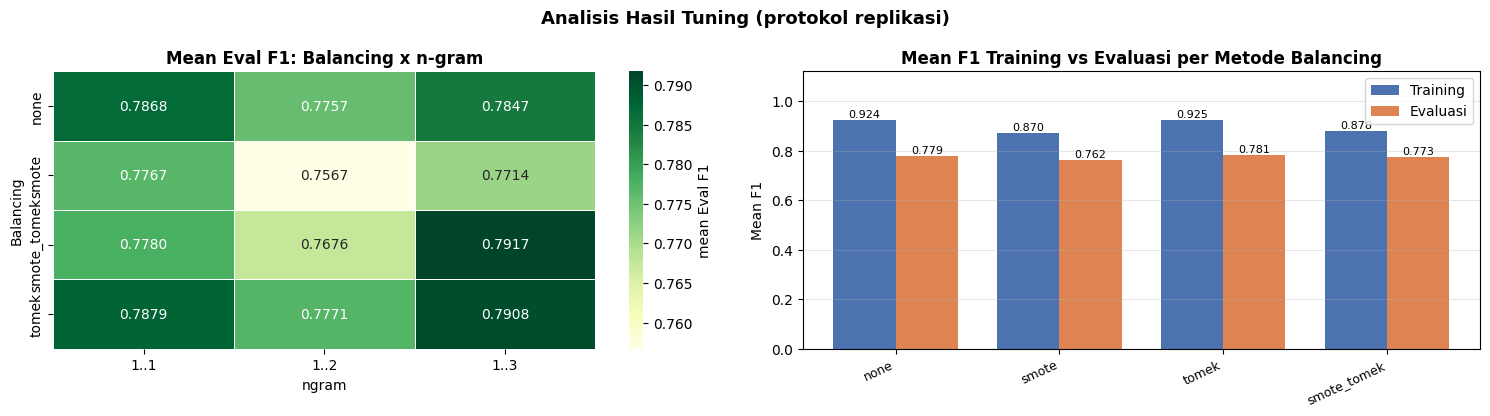

Grafik disimpan: tuning_heatmap.png


In [ ]:
# -- Visualisasi hasil tuning --
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

pivot_ng = df_tuning.pivot_table(values='f1', index='balancing', columns='ngram', aggfunc='mean')
sns.heatmap(pivot_ng, annot=True, fmt='.4f', cmap='YlGn', ax=axes[0],
            cbar_kws={'label': 'mean Eval F1'}, linewidths=0.5, linecolor='white')
axes[0].set_title('Mean Eval F1: Balancing x n-gram', fontweight='bold')
axes[0].set_xlabel('ngram'); axes[0].set_ylabel('Balancing')

bal_tr = df_tuning.groupby('balancing')['train_f1'].mean()
bal_ev = df_tuning.groupby('balancing')['f1'].mean()
order  = [b for b in BALANCE_METHODS if b in bal_ev.index]
xs     = np.arange(len(order)); w = 0.38
axes[1].bar(xs - w/2, [bal_tr[b] for b in order], w, label='Training', color='#4C72B0')
axes[1].bar(xs + w/2, [bal_ev[b] for b in order], w, label='Evaluasi', color='#DD8452')
for i, b in enumerate(order):
    axes[1].text(i - w/2, bal_tr[b] + 0.01, f'{bal_tr[b]:.3f}', ha='center', fontsize=8)
    axes[1].text(i + w/2, bal_ev[b] + 0.01, f'{bal_ev[b]:.3f}', ha='center', fontsize=8)
axes[1].set_xticks(xs); axes[1].set_xticklabels(order, rotation=25, ha='right', fontsize=9)
axes[1].set_title('Mean F1 Training vs Evaluasi per Metode Balancing', fontweight='bold')
axes[1].set_ylabel('Mean F1'); axes[1].set_ylim(0, 1.12)
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Analisis Hasil Tuning (protokol replikasi)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tuning_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()
print('Grafik disimpan: tuning_heatmap.png')


In [ ]:
# ================================================================
# EKSTRAK PARAMETER TERBAIK -> dipakai otomatis untuk training
# ================================================================
best_row_global = df_global.iloc[0]

best_ngram_s = best_row_global['ngram']
best_min_df  = best_row_global['min_df']
best_alpha   = float(best_row_global['alpha'])
best_bal_gl  = best_row_global['balancing']

best_log = next(r for r in tuning_log
                if r['ngram']     == best_ngram_s
                and r['min_df']   == best_min_df
                and r['alpha']    == best_alpha
                and r['balancing']== best_bal_gl)

BEST_COUNTVEC_CFG_RAW = best_log['_countvec_cfg']

COUNTVEC_CONFIG_BEST = {
    'analyzer' : BEST_COUNTVEC_CFG_RAW.get('analyzer',  'word'),
    'min_df'   : BEST_COUNTVEC_CFG_RAW.get('min_df',    2),
    'max_df'   : BEST_COUNTVEC_CFG_RAW.get('max_df',    0.95),
    'ngram_min': BEST_COUNTVEC_CFG_RAW.get('ngram_min', 1),
    'ngram_max': BEST_COUNTVEC_CFG_RAW.get('ngram_max', 2),
    'alpha'    : best_alpha,
    'chi2_k'   : None,
}

# Best balancing PER ASPEK (top-1 F1 evaluasi tiap aspek)
BEST_BAL_PER_ASPEK = {}
for asp in ASPECTS:
    sub = df_tuning[df_tuning['aspek_key'] == asp]
    if not sub.empty:
        BEST_BAL_PER_ASPEK[asp] = sub.loc[sub['f1'].idxmax(), 'balancing']

print('=' * 65)
print('PARAMETER TERBAIK DARI TUNING')
print('=' * 65)
print('  CountVectorizer config:')
for k, v in COUNTVEC_CONFIG_BEST.items():
    print(f'    {k:<12s}: {v}')
print(f'  Best balancing global   : {best_bal_gl}')
print('  Best balancing per aspek:')
for asp, bal in BEST_BAL_PER_ASPEK.items():
    print(f'    {ASPECT_LABELS[asp]:<26s}: {bal}')
print()
print('Parameter ini OTOMATIS digunakan untuk training di bawah.')


PARAMETER TERBAIK DARI TUNING
  CountVectorizer config:
    analyzer    : word
    min_df      : 3
    max_df      : 0.9
    ngram_min   : 1
    ngram_max   : 3
    alpha       : 0.1
    chi2_k      : None
  Best balancing global   : smote_tomek
  Best balancing per aspek:
    Gameplay & Storyline      : tomek
    Aksesibilitas             : smote_tomek
    Grafis & Performa         : tomek
    Fitur                     : smote_tomek
    Others                    : smote_tomek

Parameter ini OTOMATIS digunakan untuk training di bawah.


## 9. Training & Evaluasi dengan 10-Fold Cross-Validation

**Alur replikasi (per aspek, per metode balancing):**

1. Ambil data aspek — hanya ulasan dengan label ≠ 0 (Positif vs Negatif).
2. **CountVectorizer** di-*fit* pada seluruh data aspek tersebut → matriks Bag-of-Words.
3. **Balancing** diterapkan pada seluruh matriks (none / ROS / RUS / SMOTE / Tomek / SMOTE-Tomek).
4. Data hasil balancing dibagi menjadi **10 fold** (StratifiedKFold, shuffle=True).
5. Tiap fold: MultinomialNB dilatih pada 9 fold → dicatat **hasil saat training** (prediksi pada data latih) **dan hasil saat evaluasi** (prediksi pada fold uji).
6. Dilaporkan **Mean ± Std** untuk kedua kelompok metrik + **Gap** = F1 training − F1 evaluasi sebagai indikator *overfitting*.

In [ ]:
print('=' * 118)
print(f'TRAINING & EVALUASI - {K_FOLDS}-FOLD CV (K-FOLD SETELAH BALANCING)')
print('=' * 118)

# Gunakan parameter dari tuning jika tersedia, else fallback ke default
try:
    _cv_use  = COUNTVEC_CONFIG_BEST
    _bal_use = BEST_BAL_PER_ASPEK
    print('  Menggunakan parameter hasil tuning:')
    print(f"    MNB alpha  : {_cv_use['alpha']}")
    print(f"    ngram_max  : {_cv_use['ngram_max']}")
    print(f"    min_df     : {_cv_use['min_df']}")
except NameError:
    _cv_use  = COUNTVEC_CONFIG
    _bal_use = {}
    print('  [!] Tuning belum dijalankan - memakai COUNTVEC_CONFIG default')

print(f'\nDataset  : {len(df)} ulasan')
print(f'K-Fold   : {K_FOLDS} (StratifiedKFold, shuffle=True, random_state={RANDOM_STATE})')
print(f'Protokol : {CV_PROTOCOL}')
print(f'CountVec : {_cv_use}')

all_results = {}
t_start = time.time()

for aspect in ASPECTS:
    X, y = get_aspect_data(df, aspect)
    if X is None:
        print(f'\n[{aspect.upper()}] SKIP - data tidak memenuhi syarat (kolom hilang / <20 data / 1 kelas)')
        all_results[aspect] = {'skipped': True, 'reason': 'data tidak memenuhi syarat'}
        continue

    rekom = _bal_use.get(aspect, 'ros')
    print(f'\n{"="*118}')
    print(f'[{aspect.upper()}] {ASPECT_LABELS[aspect]} | n={len(y)} '
          f'| Positif={int((y==1).sum())} Negatif={int((y==-1).sum())} '
          f'| rekomendasi tuning: {rekom}')
    print('=' * 118)

    scenarios = {}
    for bal in BALANCE_METHODS:
        try:
            res = run_cv(X, y, bal, _cv_use, k=K_FOLDS)
            scenarios[bal] = res

            mark = '  <- BEST (tuning)' if bal == rekom else ''
            db, da = res['dist_before'], res['dist_after']
            print(f"\n  Balancing: {BALANCE_LABELS[bal]} ({bal}){mark}   k={res['k_used']}")
            print(f"    Data sebelum balancing : Pos={db.get(1,0):<5d} Neg={db.get(-1,0):<5d} Total={res['n_before']}")
            print(f"    Data sesudah balancing : Pos={da.get(1,0):<5d} Neg={da.get(-1,0):<5d} Total={res['n_after']}"
                  f"   (K-Fold dilakukan pada data ini)")
            print(f"    Ukuran vocabulary      : {res['vocab_size']} fitur")
            print()
            print(f"    {'':<6s}{'--------- HASIL TRAINING ---------':^36s} {'--------- HASIL EVALUASI ---------':^36s}")
            print(f"    {'Fold':<6s}{'Acc':>9s}{'Prec':>9s}{'Rec':>9s}{'F1':>9s}"
                  f"{'Acc':>10s}{'Prec':>9s}{'Rec':>9s}{'F1':>9s}{'GapF1':>9s}")
            print('    ' + '-' * 88)
            for fi, (ftr, fev) in enumerate(zip(res['train_fold_metrics'], res['fold_metrics']), 1):
                print(f"    {fi:<6d}{ftr['accuracy']:>9.4f}{ftr['precision']:>9.4f}"
                      f"{ftr['recall']:>9.4f}{ftr['f1']:>9.4f}"
                      f"{fev['accuracy']:>10.4f}{fev['precision']:>9.4f}"
                      f"{fev['recall']:>9.4f}{fev['f1']:>9.4f}"
                      f"{ftr['f1']-fev['f1']:>+9.4f}")
            mt, st = res['train_metrics'], res['train_metrics_std']
            me, se = res['metrics'], res['metrics_std']
            print('    ' + '-' * 88)
            print(f"    {'Mean':<6s}{mt['accuracy']:>9.4f}{mt['precision']:>9.4f}{mt['recall']:>9.4f}{mt['f1']:>9.4f}"
                  f"{me['accuracy']:>10.4f}{me['precision']:>9.4f}{me['recall']:>9.4f}{me['f1']:>9.4f}"
                  f"{res['gap']['f1']:>+9.4f}")
            print(f"    {'Std':<6s}{st['accuracy']:>9.4f}{st['precision']:>9.4f}{st['recall']:>9.4f}{st['f1']:>9.4f}"
                  f"{se['accuracy']:>10.4f}{se['precision']:>9.4f}{se['recall']:>9.4f}{se['f1']:>9.4f}")
            print(f"    => Training F1 = {mt['f1']:.4f} +/- {st['f1']:.4f}   |   "
                  f"Evaluasi F1 = {me['f1']:.4f} +/- {se['f1']:.4f}")
        except Exception as e:
            print(f'\n  Balancing: {bal} -> ERROR: {e}')
            scenarios[bal] = {'error': str(e)}

    valid_sc    = {k: v for k, v in scenarios.items() if 'metrics' in v}
    best_bal_f1 = max(valid_sc.keys(), key=lambda b: valid_sc[b]['metrics']['f1']) if valid_sc else None

    all_results[aspect] = {
        'label'           : ASPECT_LABELS[aspect],
        'n_total'         : int(len(y)),
        'n_folds'         : K_FOLDS,
        'protocol'        : CV_PROTOCOL,
        'scenarios'       : scenarios,
        'best_scenario'   : best_bal_f1,
        'best_from_tuning': rekom,
        'best_f1'         : valid_sc[best_bal_f1]['metrics']['f1'] if best_bal_f1 else None,
    }
    if best_bal_f1:
        print(f"\n  -> Best mean F1 (evaluasi): {best_bal_f1} "
              f"(F1={all_results[aspect]['best_f1']:.4f} +/- "
              f"{valid_sc[best_bal_f1]['metrics_std']['f1']:.4f})")

t_total = time.time() - t_start
print(f'\n{"="*118}')
print(f'Training {K_FOLDS}-fold CV selesai dalam {t_total:.1f}s')


TRAINING & EVALUASI - 10-FOLD CV (K-FOLD SETELAH BALANCING)
  Menggunakan parameter hasil tuning:
    MNB alpha  : 0.1
    ngram_max  : 3
    min_df     : 3

Dataset  : 2793 ulasan
K-Fold   : 10 (StratifiedKFold, shuffle=True, random_state=42)
Protokol : balance_then_kfold
CountVec : {'analyzer': 'word', 'min_df': 3, 'max_df': 0.9, 'ngram_min': 1, 'ngram_max': 3, 'alpha': 0.1, 'chi2_k': None}

[GS] Gameplay & Storyline | n=1137 | Positif=975 Negatif=162 | rekomendasi tuning: tomek

  Balancing: Tanpa Balancing (none)   k=10
    Data sebelum balancing : Pos=975   Neg=162   Total=1137
    Data sesudah balancing : Pos=975   Neg=162   Total=1137   (K-Fold dilakukan pada data ini)
    Ukuran vocabulary      : 657 fitur

           --------- HASIL TRAINING ---------   --------- HASIL EVALUASI --------- 
    Fold        Acc     Prec      Rec       F1       Acc     Prec      Rec       F1    GapF1
    ----------------------------------------------------------------------------------------
    1

### 9.1 Rekap Per-Fold: Hasil Training vs Hasil Evaluasi

Tabel lengkap tiap fold (metrik training **dan** evaluasi) beserta ringkasan Mean ± Std per aspek × balancing, disimpan ke CSV.

In [ ]:
cv_rows, summary_rows_cv = [], []
for asp, info in all_results.items():
    if info.get('skipped'):
        continue
    for bal, sc in info['scenarios'].items():
        if 'metrics' not in sc:
            continue
        for fold_i, (ftr, fev) in enumerate(zip(sc['train_fold_metrics'], sc['fold_metrics']), 1):
            cv_rows.append({
                'Aspek': ASPECT_LABELS[asp], 'aspek_key': asp, 'Balancing': bal, 'Fold': fold_i,
                'Train_Accuracy': ftr['accuracy'], 'Train_Precision': ftr['precision'],
                'Train_Recall': ftr['recall'], 'Train_F1': ftr['f1'],
                'Eval_Accuracy': fev['accuracy'], 'Eval_Precision': fev['precision'],
                'Eval_Recall': fev['recall'], 'Eval_F1': fev['f1'],
                'Gap_F1': round(ftr['f1'] - fev['f1'], 4),
            })
        mt, st = sc['train_metrics'], sc['train_metrics_std']
        me, se = sc['metrics'], sc['metrics_std']
        summary_rows_cv.append({
            'Aspek': ASPECT_LABELS[asp], 'aspek_key': asp, 'Balancing': bal,
            'Train_Acc_mean': mt['accuracy'], 'Train_Acc_std': st['accuracy'],
            'Train_F1_mean' : mt['f1'],       'Train_F1_std' : st['f1'],
            'Eval_Acc_mean' : me['accuracy'], 'Eval_Acc_std' : se['accuracy'],
            'Eval_Prec_mean': me['precision'],'Eval_Prec_std': se['precision'],
            'Eval_Rec_mean' : me['recall'],   'Eval_Rec_std' : se['recall'],
            'Eval_F1_mean'  : me['f1'],       'Eval_F1_std'  : se['f1'],
            'Gap_F1'        : sc['gap']['f1'],
            'n_sebelum'     : sc.get('n_before'), 'n_sesudah': sc.get('n_after'),
            'Best'          : bal == info.get('best_scenario'),
        })

df_cv_folds   = pd.DataFrame(cv_rows)
df_cv_summary = pd.DataFrame(summary_rows_cv)

print(f'=== HASIL AKHIR CROSS-VALIDATION (K={K_FOLDS}) - TRAINING vs EVALUASI (Mean +/- Std) ===')
print(f"{'Aspek':<24s}{'Balancing':<14s}{'Train Acc':>18s}{'Train F1':>18s}"
      f"{'Eval Acc':>18s}{'Eval F1':>18s}{'Gap F1':>9s}")
print('-' * 120)
for asp in ASPECTS:
    sub = df_cv_summary[df_cv_summary['aspek_key'] == asp]
    if sub.empty:
        continue
    for _, row in sub.iterrows():
        mark = '  <- BEST' if row['Best'] else ''
        print(f"{row['Aspek']:<24s}{row['Balancing']:<14s}"
              f"{row['Train_Acc_mean']:>11.4f} +/-{row['Train_Acc_std']:>5.4f}"
              f"{row['Train_F1_mean']:>11.4f} +/-{row['Train_F1_std']:>5.4f}"
              f"{row['Eval_Acc_mean']:>11.4f} +/-{row['Eval_Acc_std']:>5.4f}"
              f"{row['Eval_F1_mean']:>11.4f} +/-{row['Eval_F1_std']:>5.4f}"
              f"{row['Gap_F1']:>+9.4f}{mark}")
    print('-' * 120)

cv_folds_path   = OUTPUT_DIR / 'cv_results_per_fold.csv'
cv_summary_path = OUTPUT_DIR / 'cv_results_summary.csv'
df_cv_folds.drop(columns=['aspek_key'], errors='ignore').to_csv(cv_folds_path, index=False, encoding='utf-8')
df_cv_summary.drop(columns=['aspek_key'], errors='ignore').to_csv(cv_summary_path, index=False, encoding='utf-8')
print(f'\n[OK] Hasil per fold disimpan : {cv_folds_path}')
print(f'[OK] Ringkasan CV disimpan   : {cv_summary_path}')

print('\n=== Tabel Per Fold (Training & Evaluasi) ===')
display(df_cv_folds.drop(columns=['aspek_key'], errors='ignore'))
print('=== Tabel Ringkasan (Mean +/- Std) ===')
display(df_cv_summary.drop(columns=['aspek_key'], errors='ignore'))


=== HASIL AKHIR CROSS-VALIDATION (K=10) - TRAINING vs EVALUASI (Mean +/- Std) ===
Aspek                   Balancing              Train Acc          Train F1          Eval Acc           Eval F1   Gap F1
------------------------------------------------------------------------------------------------------------------------
Gameplay & Storyline    none               0.9636 +/-0.0031     0.9635 +/-0.0031     0.8813 +/-0.0305     0.8804 +/-0.0325  +0.0831  <- BEST
Gameplay & Storyline    smote              0.8602 +/-0.0518     0.8587 +/-0.0532     0.8082 +/-0.0518     0.8062 +/-0.0538  +0.0525
Gameplay & Storyline    tomek              0.9634 +/-0.0020     0.9633 +/-0.0019     0.8810 +/-0.0313     0.8796 +/-0.0291  +0.0837
Gameplay & Storyline    smote_tomek        0.8933 +/-0.0422     0.8926 +/-0.0433     0.8452 +/-0.0491     0.8441 +/-0.0507  +0.0485
------------------------------------------------------------------------------------------------------------------------
Aksesibilitas      

,Aspek,Balancing,Fold,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Eval_Accuracy,Eval_Precision,Eval_Recall,Eval_F1,Gap_F1
0,Gameplay & Storyline,none,1,0.9599,0.9596,0.9599,0.9597,0.8509,0.8548,0.8509,0.8528,0.1069
1,Gameplay & Storyline,none,2,0.9658,0.9655,0.9658,0.9656,0.8684,0.8719,0.8684,0.8701,0.0955
2,Gameplay & Storyline,none,3,0.9580,0.9581,0.9580,0.9580,0.8509,0.8628,0.8509,0.8561,0.1019
3,Gameplay & Storyline,none,4,0.9629,0.9636,0.9629,0.9632,0.9123,0.9059,0.9123,0.9069,0.0563
4,Gameplay & Storyline,none,5,0.9668,0.9672,0.9668,0.9670,0.8947,0.8947,0.8947,0.8947,0.0723
...,...,...,...,...,...,...,...,...,...,...,...,...
195,Others,smote_tomek,6,0.7622,0.7637,0.7622,0.7618,0.6841,0.6912,0.6841,0.6812,0.0806
196,Others,smote_tomek,7,0.7609,0.7628,0.7609,0.7604,0.7333,0.7373,0.7333,0.7323,0.0281
197,Others,smote_tomek,8,0.7615,0.7633,0.7615,0.7611,0.7130,0.7194,0.7130,0.7111,0.0500
198,Others,smote_tomek,9,0.7606,0.7629,0.7606,0.7601,0.7035,0.7048,0.7035,0.7030,0.0571


=== Tabel Ringkasan (Mean +/- Std) ===


,Aspek,Balancing,Train_Acc_mean,Train_Acc_std,Train_F1_mean,Train_F1_std,Eval_Acc_mean,Eval_Acc_std,Eval_Prec_mean,Eval_Prec_std,Eval_Rec_mean,Eval_Rec_std,Eval_F1_mean,Eval_F1_std,Gap_F1,n_sebelum,n_sesudah,Best
0,Gameplay & Storyline,none,0.9636,0.0031,0.9635,0.0031,0.8813,0.0305,0.8809,0.0345,0.8813,0.0305,0.8804,0.0325,0.0831,1137,1137,True
1,Gameplay & Storyline,smote,0.8602,0.0518,0.8587,0.0532,0.8082,0.0518,0.8184,0.0440,0.8082,0.0518,0.8062,0.0538,0.0525,1137,1950,False
2,Gameplay & Storyline,tomek,0.9634,0.0020,0.9633,0.0019,0.8810,0.0313,0.8803,0.0283,0.8810,0.0313,0.8796,0.0291,0.0837,1137,1134,False
3,Gameplay & Storyline,smote_tomek,0.8933,0.0422,0.8926,0.0433,0.8452,0.0491,0.8517,0.0419,0.8452,0.0491,0.8441,0.0507,0.0485,1137,1944,False
4,Aksesibilitas,none,0.9322,0.0049,0.9319,0.0049,0.7663,0.0488,0.7674,0.0514,0.7663,0.0488,0.7648,0.0504,0.1671,462,462,False
5,Aksesibilitas,smote,0.9096,0.0130,0.9096,0.0130,0.7976,0.0484,0.8010,0.0511,0.7976,0.0484,0.7971,0.0482,0.1125,462,622,False
6,Aksesibilitas,tomek,0.9343,0.0057,0.9341,0.0057,0.7587,0.0697,0.7617,0.0698,0.7587,0.0697,0.7576,0.0703,0.1765,462,460,False
7,Aksesibilitas,smote_tomek,0.9121,0.0154,0.9120,0.0154,0.8026,0.0445,0.8086,0.0478,0.8026,0.0445,0.8018,0.0444,0.1102,462,618,True
8,Grafis & Performa,none,0.9240,0.0065,0.9240,0.0064,0.8025,0.0417,0.8044,0.0389,0.8025,0.0417,0.8013,0.0406,0.1227,790,790,False
9,Grafis & Performa,smote,0.8638,0.0518,0.8632,0.0526,0.7780,0.0546,0.7851,0.0475,0.7780,0.0546,0.7759,0.0581,0.0873,790,1154,False


### 9.2 Visualisasi Training vs Evaluasi

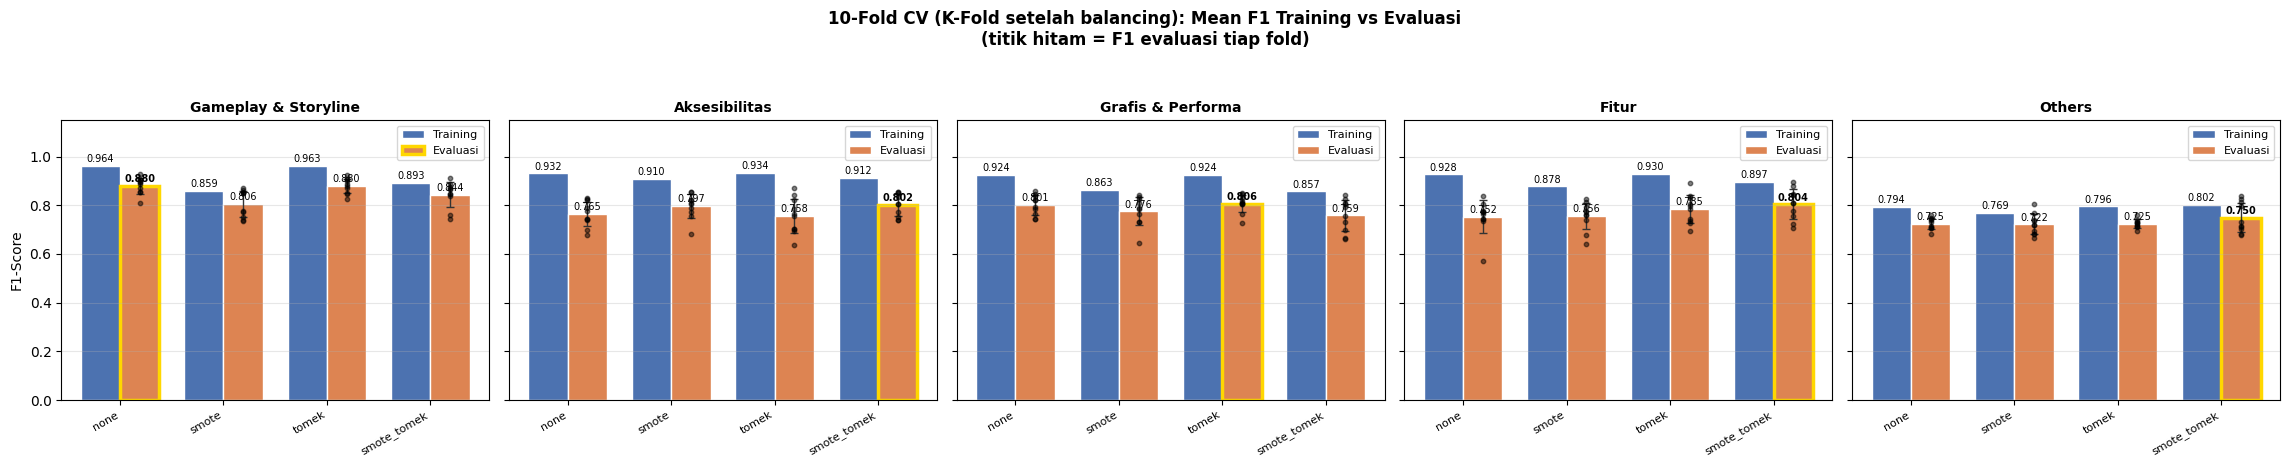

[OK] Grafik disimpan: /content/output_replikasi/train_vs_eval_f1.png


In [ ]:
# -- Grafik 1: Mean F1 Training vs Evaluasi per Aspek x Balancing --
valid_aspects = [a for a in ASPECTS
                 if isinstance(all_results.get(a), dict)
                 and not all_results[a].get('skipped')
                 and all_results[a].get('scenarios')]

if valid_aspects:
    fig, axes = plt.subplots(1, len(valid_aspects),
                             figsize=(4.6 * len(valid_aspects), 4.4), sharey=True)
    if len(valid_aspects) == 1:
        axes = [axes]

    for ax, asp in zip(axes, valid_aspects):
        scen  = all_results[asp]['scenarios']
        bals  = [b for b in BALANCE_METHODS if 'metrics' in scen.get(b, {})]
        tr_m  = [scen[b]['train_metrics']['f1'] for b in bals]
        ev_m  = [scen[b]['metrics']['f1'] for b in bals]
        ev_s  = [scen[b]['metrics_std']['f1'] for b in bals]
        best  = all_results[asp].get('best_scenario')

        xs = np.arange(len(bals)); w = 0.38
        ax.bar(xs - w/2, tr_m, w, label='Training', color='#4C72B0', edgecolor='white')
        bars = ax.bar(xs + w/2, ev_m, w, yerr=ev_s, capsize=3, label='Evaluasi',
                      color='#DD8452', edgecolor='white',
                      error_kw={'elinewidth': 1, 'ecolor': '#333333'})
        for xi, b in enumerate(bals):
            fold_f1 = [fm['f1'] for fm in scen[b]['fold_metrics']]
            ax.scatter([xi + w/2] * len(fold_f1), fold_f1, color='black', s=10, zorder=3, alpha=0.5)
        for xi, (t, e, b) in enumerate(zip(tr_m, ev_m, bals)):
            ax.text(xi - w/2, t + 0.015, f'{t:.3f}', ha='center', fontsize=7)
            ax.text(xi + w/2, e + 0.015, f'{e:.3f}', ha='center', fontsize=7,
                    fontweight='bold' if b == best else 'normal')
        for bar, b in zip(bars, bals):
            if b == best:
                bar.set_edgecolor('gold'); bar.set_linewidth(2.5)

        ax.set_title(ASPECT_LABELS[asp], fontsize=10, fontweight='bold')
        ax.set_ylim(0, 1.15)
        ax.set_ylabel('F1-Score' if asp == valid_aspects[0] else '')
        ax.set_xticks(xs); ax.set_xticklabels(bals, rotation=30, ha='right', fontsize=8)
        ax.grid(axis='y', alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(f'{K_FOLDS}-Fold CV (K-Fold setelah balancing): Mean F1 Training vs Evaluasi\n'
                 f'(titik hitam = F1 evaluasi tiap fold)',
                 fontsize=12, fontweight='bold', y=1.05)
    plt.tight_layout()
    out_img = OUTPUT_DIR / 'train_vs_eval_f1.png'
    plt.savefig(out_img, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'[OK] Grafik disimpan: {out_img}')


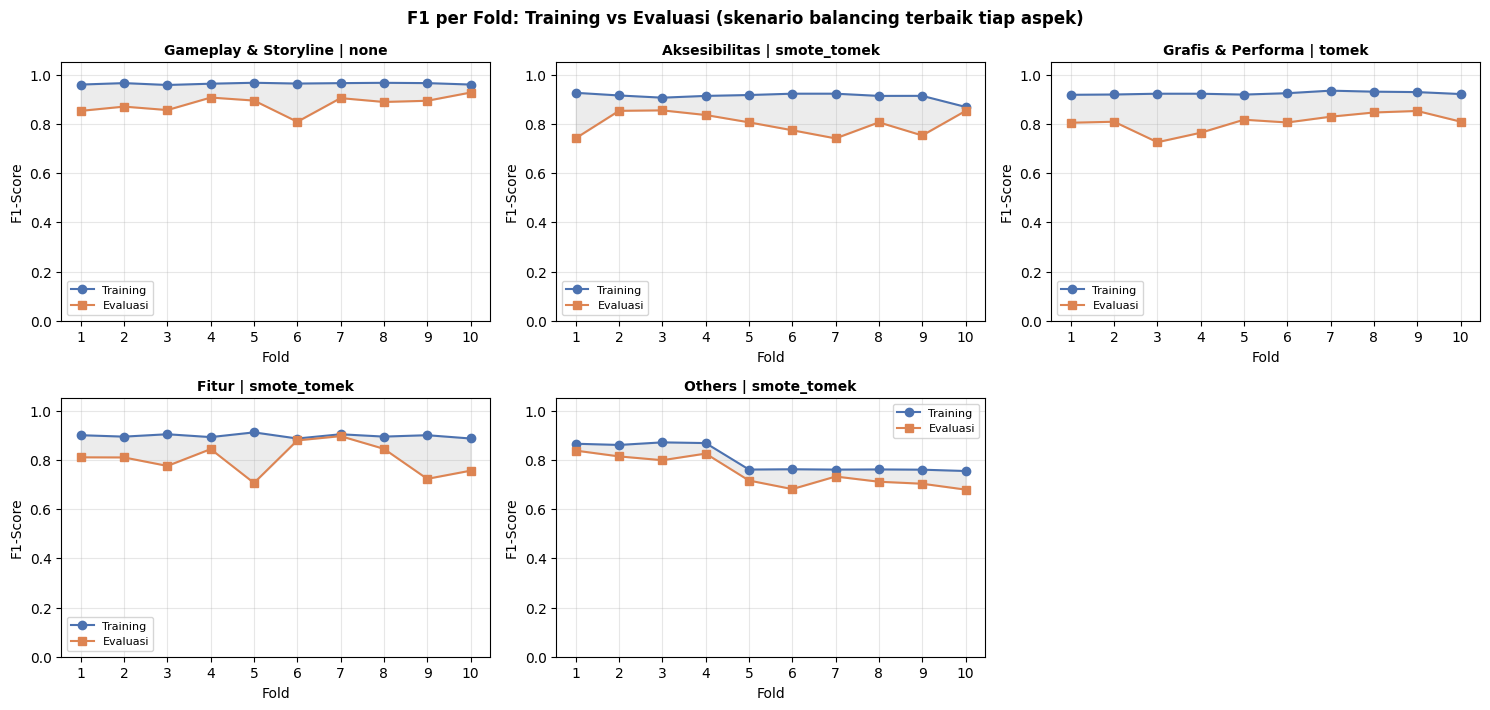

[OK] Grafik disimpan: /content/output_replikasi/f1_per_fold_train_eval.png


In [ ]:
# -- Grafik 2: Kurva F1 per fold (training vs evaluasi) untuk skenario terbaik tiap aspek --
if valid_aspects:
    ncols = min(3, len(valid_aspects))
    nrows = int(np.ceil(len(valid_aspects) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, asp in zip(axes, valid_aspects):
        bal = all_results[asp]['best_scenario']
        sc  = all_results[asp]['scenarios'][bal]
        folds  = np.arange(1, len(sc['fold_metrics']) + 1)
        f1_tr  = [m['f1'] for m in sc['train_fold_metrics']]
        f1_ev  = [m['f1'] for m in sc['fold_metrics']]
        ax.plot(folds, f1_tr, marker='o', label='Training', color='#4C72B0')
        ax.plot(folds, f1_ev, marker='s', label='Evaluasi', color='#DD8452')
        ax.fill_between(folds, f1_ev, f1_tr, color='gray', alpha=0.15)
        ax.set_title(f'{ASPECT_LABELS[asp]} | {bal}', fontsize=10, fontweight='bold')
        ax.set_xlabel('Fold'); ax.set_ylabel('F1-Score')
        ax.set_xticks(folds); ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.3); ax.legend(fontsize=8)

    for ax in axes[len(valid_aspects):]:
        ax.axis('off')

    fig.suptitle('F1 per Fold: Training vs Evaluasi (skenario balancing terbaik tiap aspek)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    out_img = OUTPUT_DIR / 'f1_per_fold_train_eval.png'
    plt.savefig(out_img, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'[OK] Grafik disimpan: {out_img}')


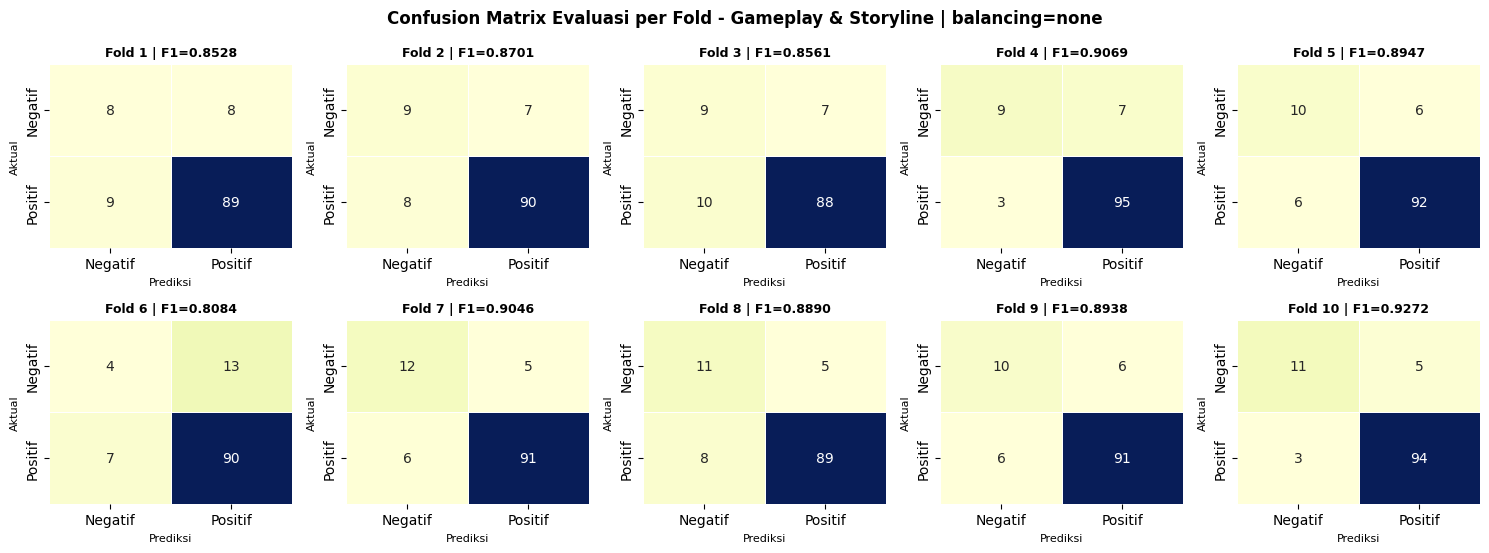

  [OK] Disimpan: /content/output_replikasi/cm_folds_gs_none.png


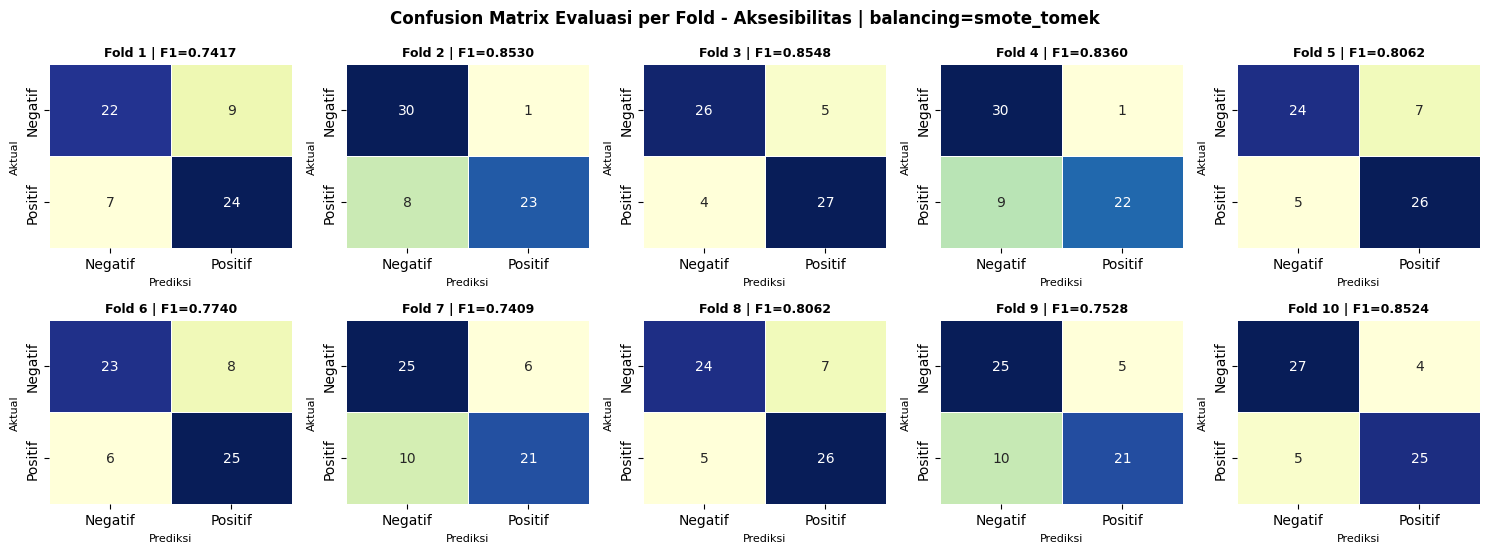

  [OK] Disimpan: /content/output_replikasi/cm_folds_a_smote_tomek.png


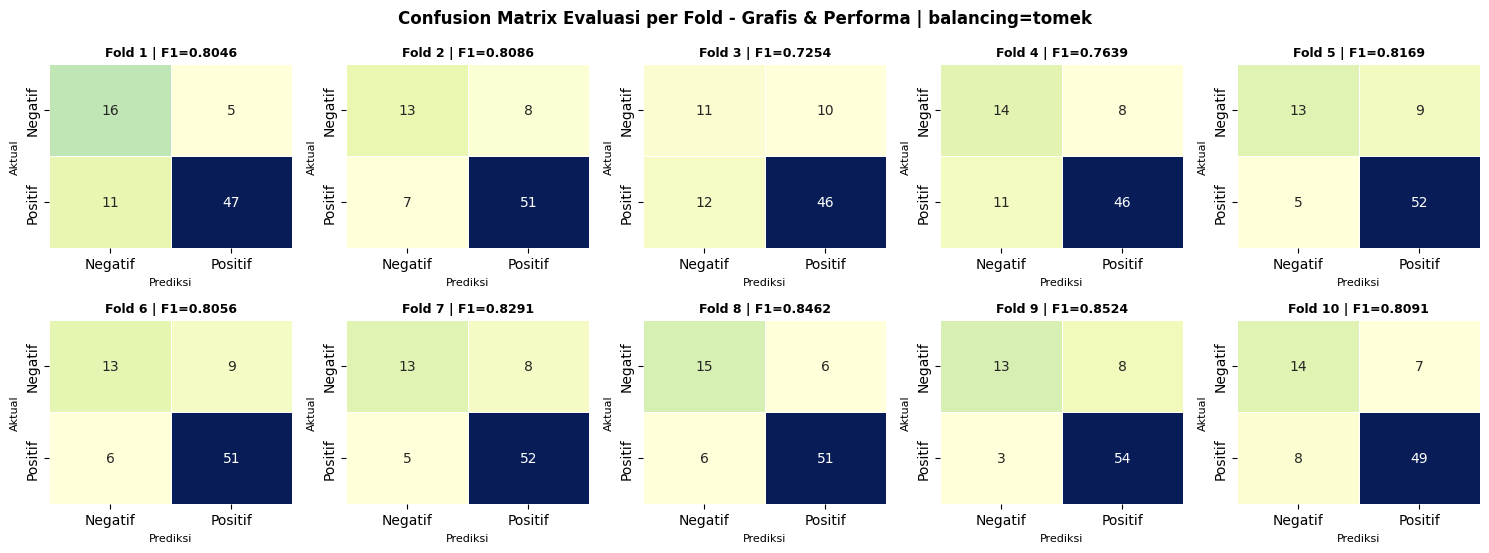

  [OK] Disimpan: /content/output_replikasi/cm_folds_gp_tomek.png


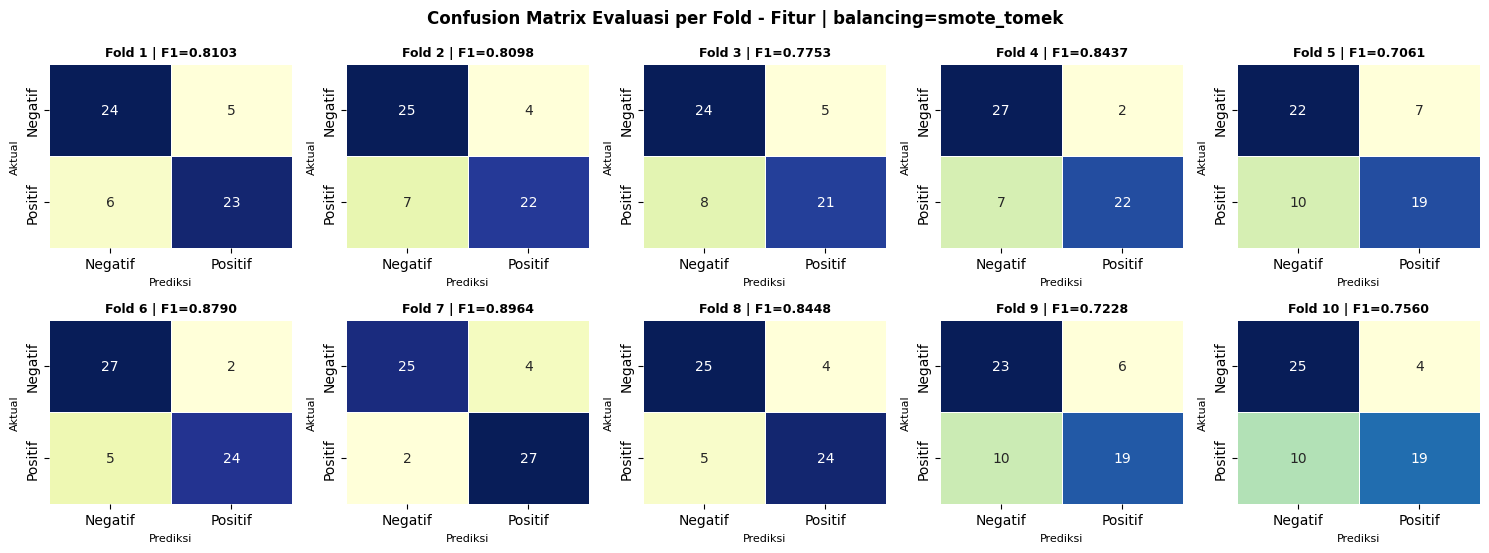

  [OK] Disimpan: /content/output_replikasi/cm_folds_f_smote_tomek.png


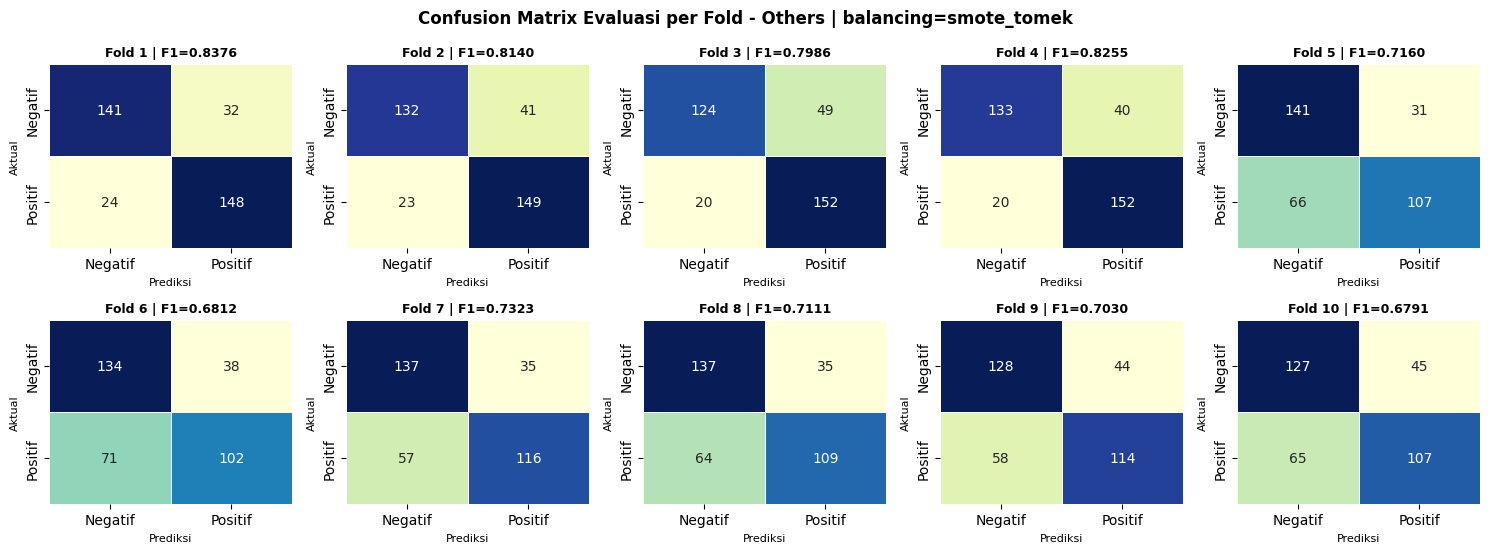

  [OK] Disimpan: /content/output_replikasi/cm_folds_others_smote_tomek.png

[OK] Confusion matrix per fold selesai


In [ ]:
# -- Confusion Matrix PER FOLD (data evaluasi, skenario terbaik tiap aspek) --
for asp in ASPECTS:
    info = all_results.get(asp, {})
    if info.get('skipped') or not info.get('best_scenario'):
        continue
    bal = info['best_scenario']
    sc  = info['scenarios'][bal]
    fold_cms = sc.get('fold_cms', [])
    if not fold_cms:
        continue

    labels = sc['class_labels']
    n_f    = len(fold_cms)
    ncols  = 5
    nrows  = int(np.ceil(n_f / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 2.8 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for i, (ax, cm_f, fm) in enumerate(zip(axes, fold_cms, sc['fold_metrics']), 1):
        sns.heatmap(cm_f, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
                    xticklabels=labels, yticklabels=labels,
                    ax=ax, linewidths=0.5, linecolor='white')
        ax.set_title(f'Fold {i} | F1={fm["f1"]:.4f}', fontsize=9, fontweight='bold')
        ax.set_xlabel('Prediksi', fontsize=8)
        ax.set_ylabel('Aktual', fontsize=8)
    for ax in axes[n_f:]:
        ax.axis('off')

    fig.suptitle(f'Confusion Matrix Evaluasi per Fold - {ASPECT_LABELS[asp]} | balancing={bal}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    cm_path = OUTPUT_DIR / f'cm_folds_{asp}_{bal}.png'
    plt.savefig(cm_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'  [OK] Disimpan: {cm_path}')

print('\n[OK] Confusion matrix per fold selesai')


## 10. Evaluasi & Confusion Matrix (Agregat 10-Fold CV)

Metrik pada tabel/grafik di bawah adalah **rata-rata lintas 10 fold**. Confusion matrix merupakan **agregat (penjumlahan) CM seluruh fold**:
- **CM Evaluasi** — tiap sampel (setelah balancing) tepat satu kali menjadi data uji.
- **CM Training** — akumulasi prediksi pada data latih di setiap fold (tiap sampel muncul K−1 kali), berguna untuk melihat pola kesalahan yang bahkan tidak bisa dipelajari model.

In [ ]:
print(f'=== RINGKASAN HASIL (Mean {K_FOLDS}-Fold CV) - TRAINING vs EVALUASI ===')
print(f"{'Aspek':<24s}{'Balancing':<14s}"
      f"{'TrAcc':>8s}{'TrF1':>8s}"
      f"{'EvAcc':>9s}{'EvPrec':>9s}{'EvRec':>8s}{'EvF1':>8s}{'Gap':>9s}")
print('-' * 96)

rows = []
for asp, info in all_results.items():
    if info.get('skipped'):
        print(f'{ASPECT_LABELS.get(asp, asp):<24s} SKIPPED - {info.get("reason", "")}')
        continue
    best = info.get('best_scenario')
    for bal, sc in info['scenarios'].items():
        if 'metrics' not in sc:
            continue
        mt, me = sc['train_metrics'], sc['metrics']
        mark = '  <- BEST' if bal == best else ''
        print(f"{ASPECT_LABELS[asp]:<24s}{bal:<14s}"
              f"{mt['accuracy']:>8.4f}{mt['f1']:>8.4f}"
              f"{me['accuracy']:>9.4f}{me['precision']:>9.4f}{me['recall']:>8.4f}{me['f1']:>8.4f}"
              f"{sc['gap']['f1']:>+9.4f}{mark}")
        rows.append({
            'Aspek': ASPECT_LABELS[asp], 'Balancing': bal,
            'Train_Accuracy': mt['accuracy'], 'Train_Precision': mt['precision'],
            'Train_Recall': mt['recall'], 'Train_F1': mt['f1'],
            'Eval_Accuracy': me['accuracy'], 'Eval_Precision': me['precision'],
            'Eval_Recall': me['recall'], 'Eval_F1': me['f1'],
            'Gap_F1': sc['gap']['f1'], 'Best': bal == best,
        })
    print('-' * 96)

df_results = pd.DataFrame(rows)
display(df_results)


=== RINGKASAN HASIL (Mean 10-Fold CV) - TRAINING vs EVALUASI ===
Aspek                   Balancing        TrAcc    TrF1    EvAcc   EvPrec   EvRec    EvF1      Gap
------------------------------------------------------------------------------------------------
Gameplay & Storyline    none            0.9636  0.9635   0.8813   0.8809  0.8813  0.8804  +0.0831  <- BEST
Gameplay & Storyline    smote           0.8602  0.8587   0.8082   0.8184  0.8082  0.8062  +0.0525
Gameplay & Storyline    tomek           0.9634  0.9633   0.8810   0.8803  0.8810  0.8796  +0.0837
Gameplay & Storyline    smote_tomek     0.8933  0.8926   0.8452   0.8517  0.8452  0.8441  +0.0485
------------------------------------------------------------------------------------------------
Aksesibilitas           none            0.9322  0.9319   0.7663   0.7674  0.7663  0.7648  +0.1671
Aksesibilitas           smote           0.9096  0.9096   0.7976   0.8010  0.7976  0.7971  +0.1125
Aksesibilitas           tomek           0.9343

,Aspek,Balancing,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Eval_Accuracy,Eval_Precision,Eval_Recall,Eval_F1,Gap_F1,Best
0,Gameplay & Storyline,none,0.9636,0.9635,0.9636,0.9635,0.8813,0.8809,0.8813,0.8804,0.0831,True
1,Gameplay & Storyline,smote,0.8602,0.8713,0.8602,0.8587,0.8082,0.8184,0.8082,0.8062,0.0525,False
2,Gameplay & Storyline,tomek,0.9634,0.9633,0.9634,0.9633,0.8810,0.8803,0.8810,0.8796,0.0837,False
3,Gameplay & Storyline,smote_tomek,0.8933,0.8991,0.8933,0.8926,0.8452,0.8517,0.8452,0.8441,0.0485,False
4,Aksesibilitas,none,0.9322,0.9319,0.9322,0.9319,0.7663,0.7674,0.7663,0.7648,0.1671,False
5,Aksesibilitas,smote,0.9096,0.9106,0.9096,0.9096,0.7976,0.8010,0.7976,0.7971,0.1125,False
6,Aksesibilitas,tomek,0.9343,0.9341,0.9343,0.9341,0.7587,0.7617,0.7587,0.7576,0.1765,False
7,Aksesibilitas,smote_tomek,0.9121,0.9130,0.9121,0.9120,0.8026,0.8086,0.8026,0.8018,0.1102,True
8,Grafis & Performa,none,0.9240,0.9239,0.9240,0.9240,0.8025,0.8044,0.8025,0.8013,0.1227,False
9,Grafis & Performa,smote,0.8638,0.8677,0.8638,0.8632,0.7780,0.7851,0.7780,0.7759,0.0873,False


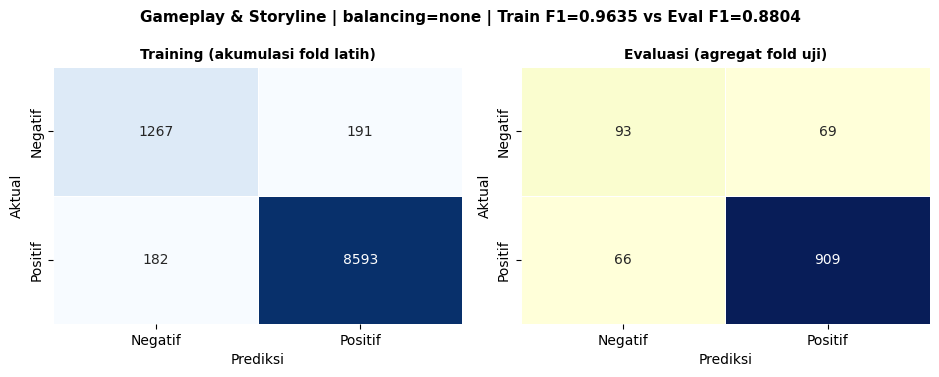

  [OK] Disimpan: /content/output_replikasi/cm_train_eval_gs_none.png


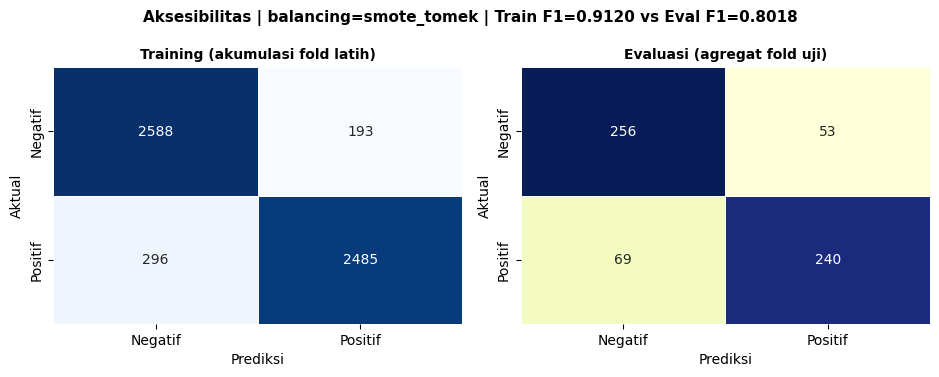

  [OK] Disimpan: /content/output_replikasi/cm_train_eval_a_smote_tomek.png


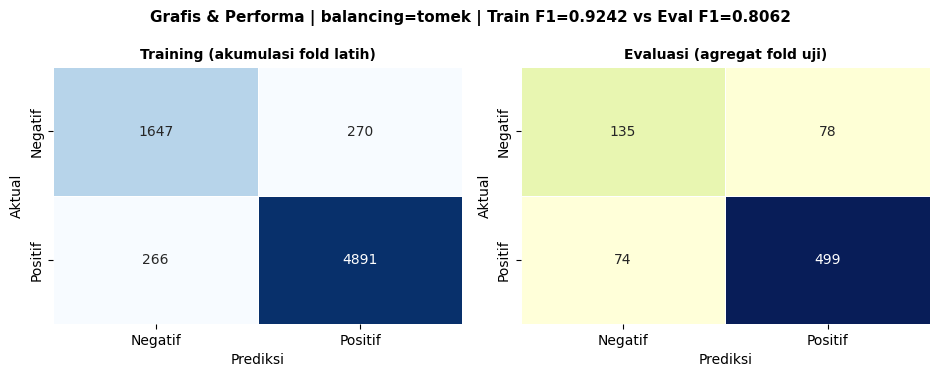

  [OK] Disimpan: /content/output_replikasi/cm_train_eval_gp_tomek.png


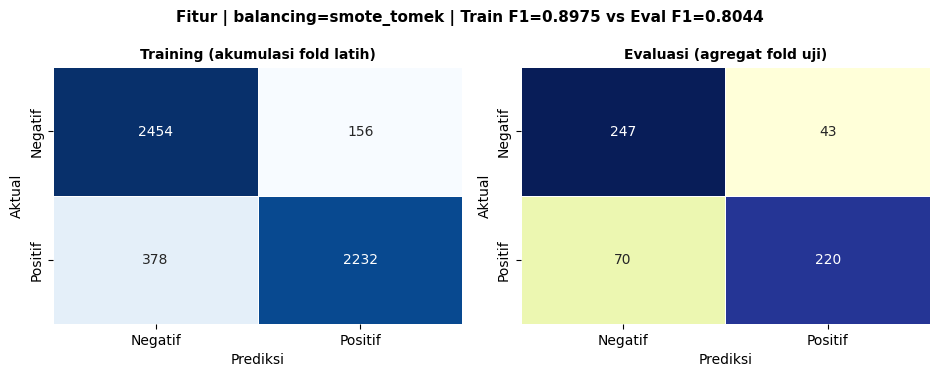

  [OK] Disimpan: /content/output_replikasi/cm_train_eval_f_smote_tomek.png


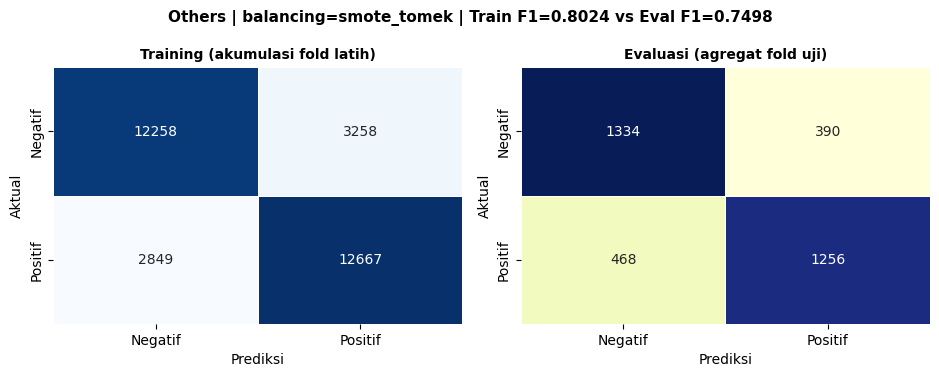

  [OK] Disimpan: /content/output_replikasi/cm_train_eval_others_smote_tomek.png

[OK] Confusion matrix agregat selesai


In [ ]:
# -- Confusion Matrix Agregat: Training vs Evaluasi (skenario terbaik tiap aspek) --
for asp in ASPECTS:
    info = all_results.get(asp, {})
    if info.get('skipped') or not info.get('best_scenario'):
        continue
    bal    = info['best_scenario']
    sc     = info['scenarios'][bal]
    labels = sc['class_labels']

    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
    for ax, key, judul, cmap in [
        (axes[0], 'cm_train', 'Training (akumulasi fold latih)', 'Blues'),
        (axes[1], 'cm',       'Evaluasi (agregat fold uji)',     'YlGnBu')]:
        cm = np.array(sc[key])
        sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                    xticklabels=labels, yticklabels=labels, ax=ax,
                    linewidths=0.5, linecolor='white')
        ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
        ax.set_title(judul, fontsize=10, fontweight='bold')

    fig.suptitle(f'{ASPECT_LABELS[asp]} | balancing={bal} | '
                 f"Train F1={sc['train_metrics']['f1']:.4f} vs Eval F1={sc['metrics']['f1']:.4f}",
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    p = OUTPUT_DIR / f'cm_train_eval_{asp}_{bal}.png'
    plt.savefig(p, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'  [OK] Disimpan: {p}')

print('\n[OK] Confusion matrix agregat selesai')


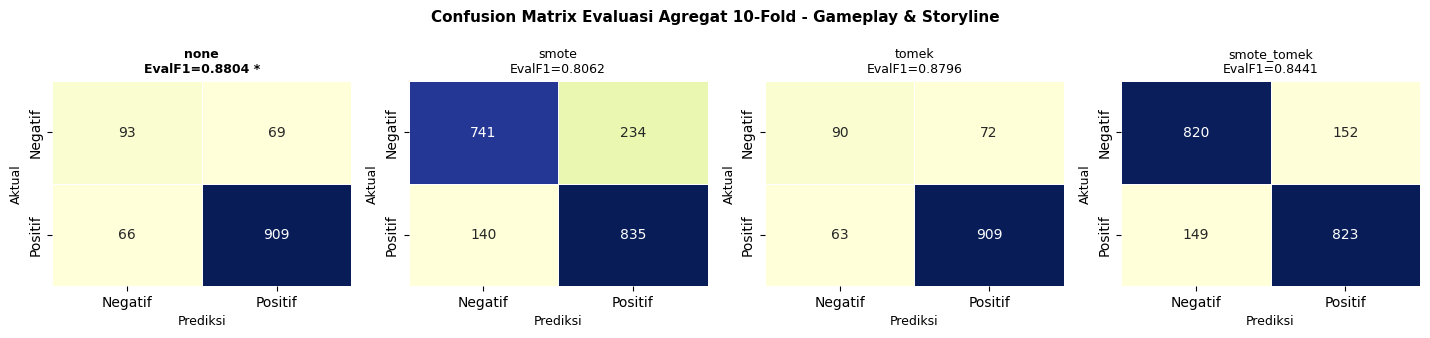

  [GS] Confusion matrix disimpan ke output_replikasi/cm_gs_*.png


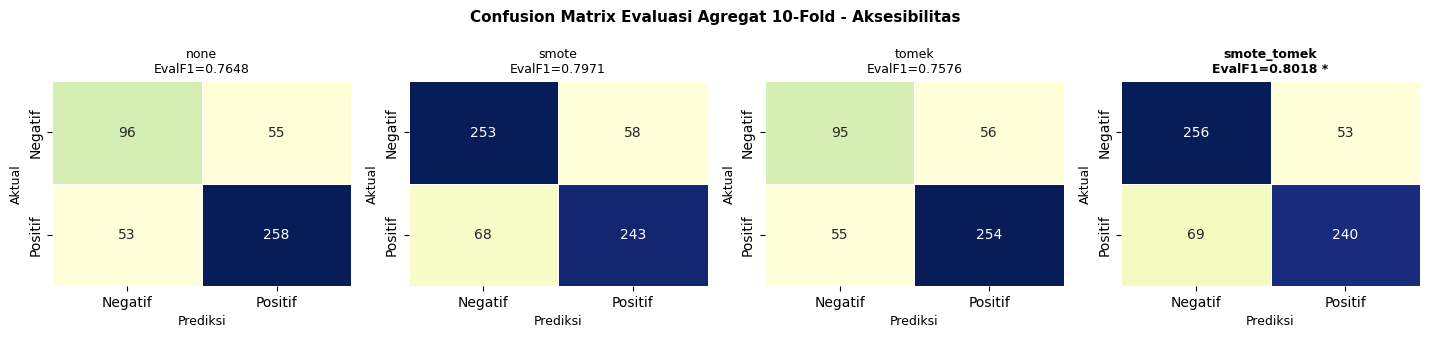

  [A] Confusion matrix disimpan ke output_replikasi/cm_a_*.png


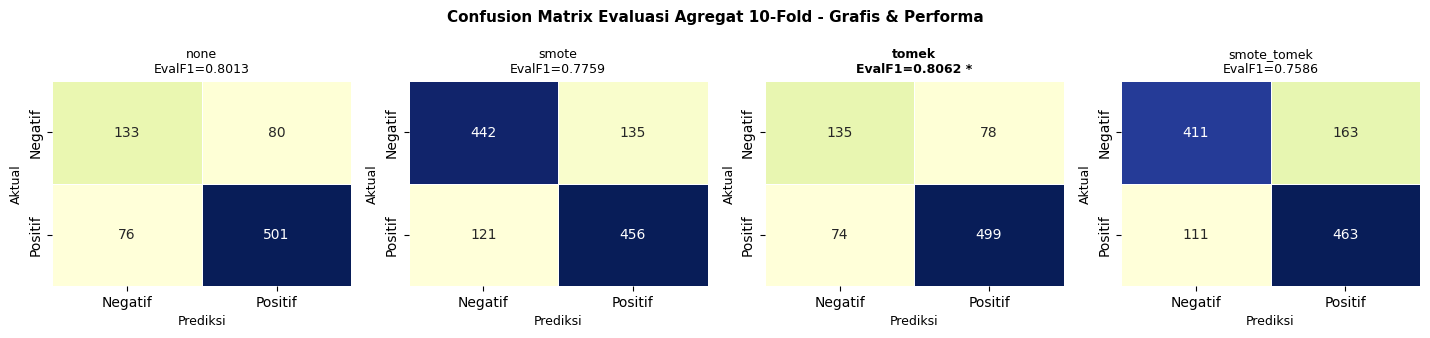

  [GP] Confusion matrix disimpan ke output_replikasi/cm_gp_*.png


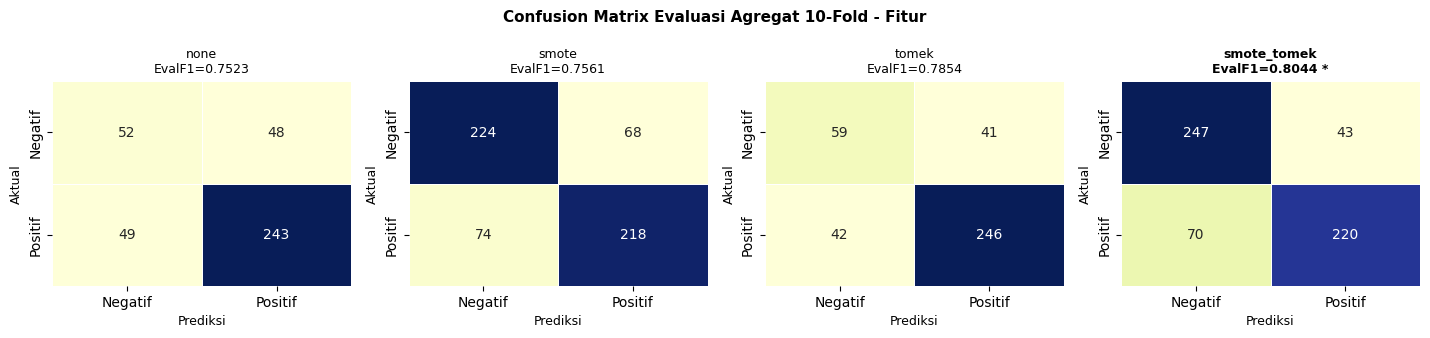

  [F] Confusion matrix disimpan ke output_replikasi/cm_f_*.png


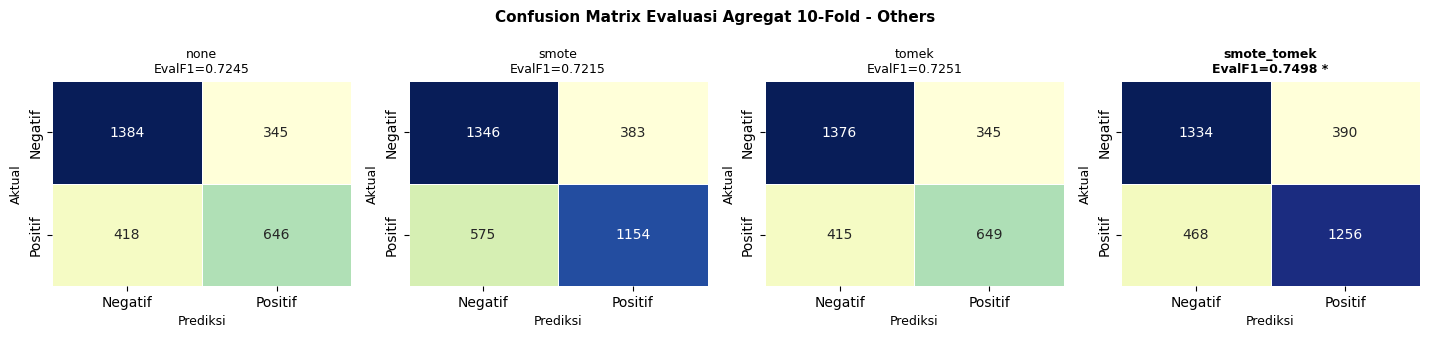

  [OTHERS] Confusion matrix disimpan ke output_replikasi/cm_others_*.png

[OK] Semua confusion matrix selesai


In [ ]:
# -- Confusion Matrix Evaluasi per Aspek x Balancing --
for asp in ASPECTS:
    info = all_results.get(asp, {})
    if info.get('skipped') or not info.get('scenarios'):
        continue

    valid_bals = [b for b in BALANCE_METHODS if 'cm' in info['scenarios'].get(b, {})]
    n_cols = len(valid_bals)
    if n_cols == 0:
        continue

    fig, axes = plt.subplots(1, n_cols, figsize=(3.6 * n_cols, 3.4))
    if n_cols == 1:
        axes = [axes]

    best = info.get('best_scenario')
    for ax, bal in zip(axes, valid_bals):
        sc     = info['scenarios'][bal]
        cm     = np.array(sc['cm'])
        labels = sc['class_labels']
        title  = f'{bal}\nEvalF1={sc["metrics"]["f1"]:.4f}' + (' *' if bal == best else '')
        sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
                    xticklabels=labels, yticklabels=labels,
                    ax=ax, cbar=False, linewidths=0.5, linecolor='white')
        ax.set_xlabel('Prediksi', fontsize=9)
        ax.set_ylabel('Aktual', fontsize=9)
        ax.set_title(title, fontsize=9, fontweight='bold' if bal == best else 'normal')

        fig_s, ax_s = plt.subplots(figsize=(4.5, 3.5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
                    xticklabels=labels, yticklabels=labels, ax=ax_s, cbar=False)
        ax_s.set_xlabel('Prediksi'); ax_s.set_ylabel('Aktual')
        ax_s.set_title(f'{ASPECT_LABELS[asp]} | {bal} (agregat {K_FOLDS}-fold)')
        fig_s.tight_layout()
        fig_s.savefig(OUTPUT_DIR / f'cm_{asp}_{bal}.png', dpi=110)
        plt.close(fig_s)

    fig.suptitle(f'Confusion Matrix Evaluasi Agregat {K_FOLDS}-Fold - {ASPECT_LABELS[asp]}',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(f'  [{asp.upper()}] Confusion matrix disimpan ke {OUTPUT_DIR.name}/cm_{asp}_*.png')

print('\n[OK] Semua confusion matrix selesai')


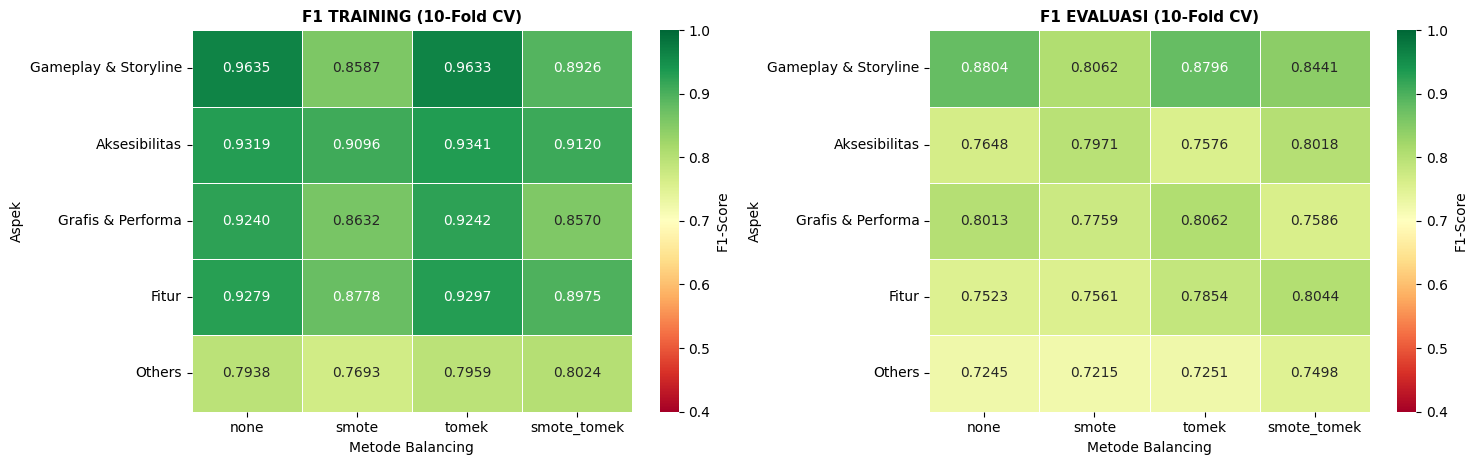

[OK] Heatmap disimpan: /content/output_replikasi/f1_heatmap_train_eval.png


In [ ]:
# -- Heatmap Ringkasan F1 (Aspek x Balancing): Training & Evaluasi --
asp_labels_list, heat_tr, heat_ev = [], [], []
for asp in ASPECTS:
    info = all_results.get(asp, {})
    if info.get('skipped'):
        continue
    row_tr, row_ev = [], []
    for bal in BALANCE_METHODS:
        sc = info['scenarios'].get(bal, {})
        row_tr.append(sc.get('train_metrics', {}).get('f1', float('nan')))
        row_ev.append(sc.get('metrics', {}).get('f1', float('nan')))
    heat_tr.append(row_tr); heat_ev.append(row_ev)
    asp_labels_list.append(ASPECT_LABELS[asp])

if heat_ev:
    fig, axes = plt.subplots(1, 2, figsize=(15, max(3, 0.95 * len(asp_labels_list))))
    for ax, data, judul in [(axes[0], heat_tr, 'F1 TRAINING'),
                            (axes[1], heat_ev, 'F1 EVALUASI')]:
        dfh = pd.DataFrame(data, index=asp_labels_list, columns=BALANCE_METHODS)
        sns.heatmap(dfh, annot=True, fmt='.4f', cmap='RdYlGn', vmin=0.4, vmax=1.0,
                    ax=ax, linewidths=0.5, linecolor='white', cbar_kws={'label': 'F1-Score'})
        ax.set_title(f'{judul} ({K_FOLDS}-Fold CV)', fontsize=11, fontweight='bold')
        ax.set_xlabel('Metode Balancing'); ax.set_ylabel('Aspek')
    plt.tight_layout()
    out_img = OUTPUT_DIR / 'f1_heatmap_train_eval.png'
    plt.savefig(out_img, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'[OK] Heatmap disimpan: {out_img}')


### 10.1 Distribusi Data Sebelum & Sesudah Balancing (per Aspek)

Karena pada protokol replikasi balancing dilakukan **sekali pada seluruh data** (bukan di dalam tiap fold), jumlah sampel tiap kelas bersifat **tunggal dan pasti** — bukan rata-rata lintas fold. Tabel ini memperlihatkan tingkat *imbalance* asli, berapa sampel yang ditambahkan (SMOTE), dan berapa yang dihapus (Tomek).

In [ ]:
dist_rows = []
dist_plot = {}

print('=' * 92)
print('DISTRIBUSI KELAS - SEBELUM vs SESUDAH BALANCING (seluruh data, sebelum dibagi K-Fold)')
print('=' * 92)

for aspect in ASPECTS:
    info = all_results.get(aspect, {})
    if info.get('skipped') or not info.get('scenarios'):
        continue
    scen = {b: sc for b, sc in info['scenarios'].items() if 'dist_after' in sc}
    if not scen:
        continue

    dist_plot[aspect] = {}
    print(f'\n[{aspect.upper()}] {ASPECT_LABELS[aspect]}')
    print(f"  {'Metode':<14}{'Positif':>9}{'Negatif':>9}{'Total':>8}   Keterangan")
    print('  ' + '-' * 72)

    base = None
    for method in BALANCE_METHODS:
        sc = scen.get(method)
        if sc is None:
            continue
        pos = int(sc['dist_after'].get(1, 0))
        neg = int(sc['dist_after'].get(-1, 0))
        tot = pos + neg
        dist_plot[aspect][method] = {'Positif': pos, 'Negatif': neg}

        if method == 'none':
            base  = (pos, neg)
            ratio = (max(pos, neg) / min(pos, neg)) if min(pos, neg) else float('inf')
            ket   = f'imbalance ratio {ratio:.2f} : 1'
        else:
            ket = f'dPos {pos - base[0]:+d}, dNeg {neg - base[1]:+d}'

        print(f'  {method:<14}{pos:>9d}{neg:>9d}{tot:>8d}   {ket}')
        dist_rows.append({'Aspek': ASPECT_LABELS[aspect], 'aspek_key': aspect,
                          'Metode': method, 'Positif': pos, 'Negatif': neg, 'Total': tot})

df_dist  = pd.DataFrame(dist_rows)
dist_csv = OUTPUT_DIR / 'distribusi_balancing.csv'
df_dist.drop(columns=['aspek_key'], errors='ignore').to_csv(dist_csv, index=False, encoding='utf-8')
print(f'\n[OK] Tabel distribusi disimpan: {dist_csv}')
display(df_dist.drop(columns=['aspek_key'], errors='ignore'))


DISTRIBUSI KELAS - SEBELUM vs SESUDAH BALANCING (seluruh data, sebelum dibagi K-Fold)

[GS] Gameplay & Storyline
  Metode          Positif  Negatif   Total   Keterangan
  ------------------------------------------------------------------------
  none                975      162    1137   imbalance ratio 6.02 : 1
  smote               975      975    1950   dPos +0, dNeg +813
  tomek               972      162    1134   dPos -3, dNeg +0
  smote_tomek         972      972    1944   dPos -3, dNeg +810

[A] Aksesibilitas
  Metode          Positif  Negatif   Total   Keterangan
  ------------------------------------------------------------------------
  none                311      151     462   imbalance ratio 2.06 : 1
  smote               311      311     622   dPos +0, dNeg +160
  tomek               309      151     460   dPos -2, dNeg +0
  smote_tomek         309      309     618   dPos -2, dNeg +158

[GP] Grafis & Performa
  Metode          Positif  Negatif   Total   Keterangan
  ----

,Aspek,Metode,Positif,Negatif,Total
0,Gameplay & Storyline,none,975,162,1137
1,Gameplay & Storyline,smote,975,975,1950
2,Gameplay & Storyline,tomek,972,162,1134
3,Gameplay & Storyline,smote_tomek,972,972,1944
4,Aksesibilitas,none,311,151,462
5,Aksesibilitas,smote,311,311,622
6,Aksesibilitas,tomek,309,151,460
7,Aksesibilitas,smote_tomek,309,309,618
8,Grafis & Performa,none,577,213,790
9,Grafis & Performa,smote,577,577,1154


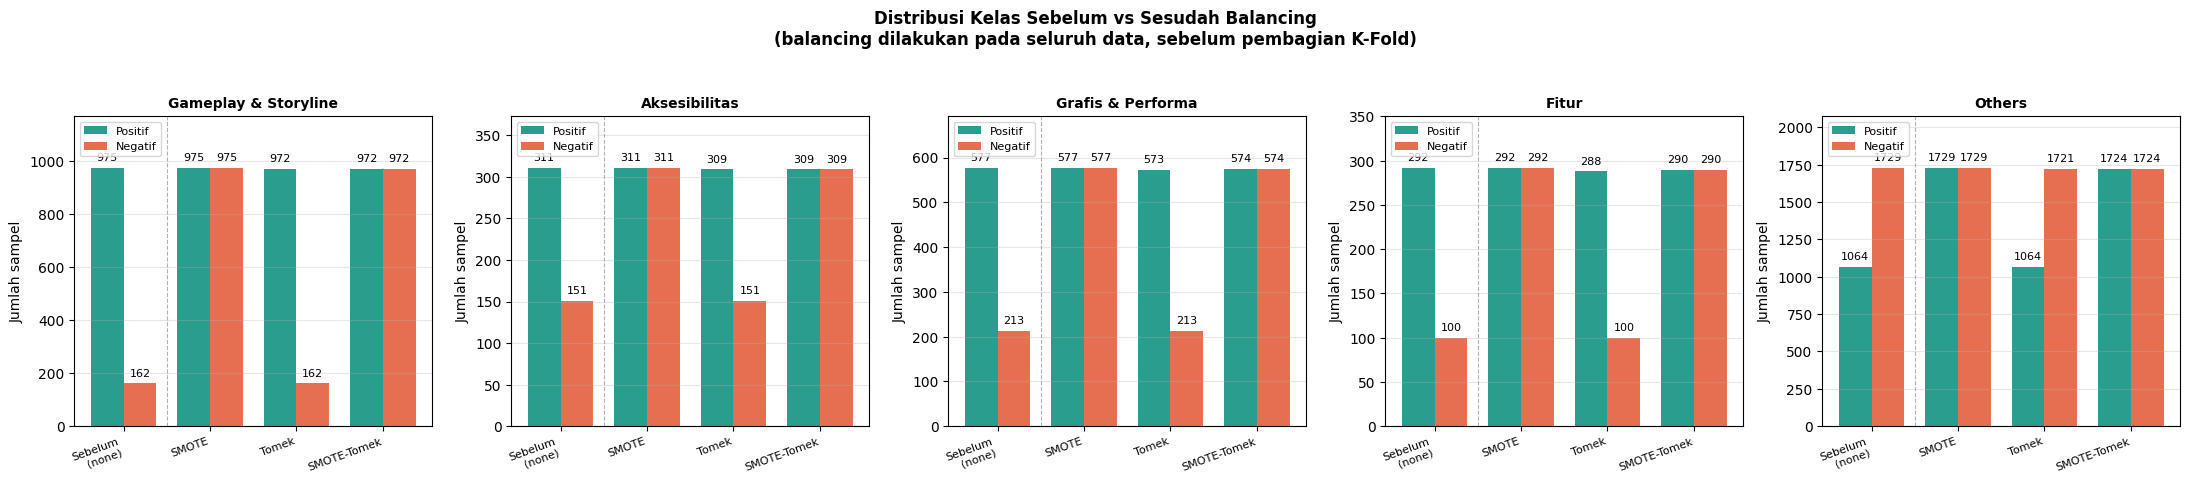

[OK] Grafik disimpan: /content/output_replikasi/balance_distribution.png


In [ ]:
# -- Grafik batang: distribusi kelas sebelum vs sesudah balancing --
method_labels = {'none': 'Sebelum\n(none)', 'ros': 'ROS', 'rus': 'RUS',
                 'smote': 'SMOTE', 'tomek': 'Tomek', 'smote_tomek': 'SMOTE-Tomek'}
asp_keys = [a for a in ASPECTS if a in dist_plot]
n_asp    = len(asp_keys)

if n_asp:
    fig, axes = plt.subplots(1, n_asp, figsize=(4.4 * n_asp, 4.6))
    if n_asp == 1:
        axes = [axes]

    C_POS, C_NEG = '#2A9D8F', '#E76F51'
    for ax, aspect in zip(axes, asp_keys):
        methods  = [m for m in BALANCE_METHODS if m in dist_plot[aspect]]
        xlabels  = [method_labels.get(m, m) for m in methods]
        pos_vals = [dist_plot[aspect][m]['Positif'] for m in methods]
        neg_vals = [dist_plot[aspect][m]['Negatif'] for m in methods]

        x = np.arange(len(methods)); w = 0.38
        b1 = ax.bar(x - w/2, pos_vals, w, label='Positif', color=C_POS)
        b2 = ax.bar(x + w/2, neg_vals, w, label='Negatif', color=C_NEG)
        ymax = max(max(pos_vals), max(neg_vals))
        for bars in (b1, b2):
            for bar in bars:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + ymax * 0.02,
                        f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=8)
        ax.axvline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
        ax.set_xticks(x); ax.set_xticklabels(xlabels, fontsize=8, rotation=20, ha='right')
        ax.set_ylim(0, ymax * 1.2)
        ax.set_title(ASPECT_LABELS[aspect], fontsize=10, fontweight='bold')
        ax.set_ylabel('Jumlah sampel')
        ax.grid(axis='y', alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle('Distribusi Kelas Sebelum vs Sesudah Balancing\n'
                 '(balancing dilakukan pada seluruh data, sebelum pembagian K-Fold)',
                 fontsize=12, fontweight='bold', y=1.04)
    plt.tight_layout()
    p = OUTPUT_DIR / 'balance_distribution.png'
    plt.savefig(p, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'[OK] Grafik disimpan: {p}')


### 10.2 Simpan Hasil Evaluasi ke JSON & CSV

In [ ]:
def json_default(o):
    if isinstance(o, np.integer):  return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray):  return o.tolist()
    return str(o)

results_serializable = {}
for asp, info in all_results.items():
    if info.get('skipped'):
        results_serializable[asp] = info
        continue
    asp_info = {k: v for k, v in info.items() if k != 'scenarios'}
    asp_info['scenarios'] = {}
    for bal, sc in info['scenarios'].items():
        sc_copy = {k: v for k, v in sc.items() if k not in ('cm', 'cm_train')}
        if 'cm' in sc:
            sc_copy['confusion_matrix']       = np.array(sc['cm']).tolist()
        if 'cm_train' in sc:
            sc_copy['confusion_matrix_train'] = np.array(sc['cm_train']).tolist()
        asp_info['scenarios'][bal] = sc_copy
    results_serializable[asp] = asp_info

json_path = OUTPUT_DIR / 'results.json'
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump({
        'protocol'       : CV_PROTOCOL,
        'k_folds'        : K_FOLDS,
        'countvec_config': COUNTVEC_CONFIG_BEST if 'COUNTVEC_CONFIG_BEST' in globals() else COUNTVEC_CONFIG,
        'aspects'        : results_serializable,
    }, f, indent=2, default=json_default, ensure_ascii=False)
print(f'[OK] Hasil evaluasi disimpan: {json_path}')

csv_path = OUTPUT_DIR / 'results_summary.csv'
df_results.to_csv(csv_path, index=False, encoding='utf-8')
print(f'[OK] Ringkasan CSV disimpan: {csv_path}')

print('\n=== Best Scenario per Aspek ===')
display(df_results[df_results['Best'] == True][
    ['Aspek', 'Balancing', 'Train_F1', 'Eval_Accuracy', 'Eval_Precision', 'Eval_Recall', 'Eval_F1', 'Gap_F1']])


[OK] Hasil evaluasi disimpan: /content/output_replikasi/results.json
[OK] Ringkasan CSV disimpan: /content/output_replikasi/results_summary.csv

=== Best Scenario per Aspek ===


,Aspek,Balancing,Train_F1,Eval_Accuracy,Eval_Precision,Eval_Recall,Eval_F1,Gap_F1
0,Gameplay & Storyline,none,0.9635,0.8813,0.8809,0.8813,0.8804,0.0831
7,Aksesibilitas,smote_tomek,0.9120,0.8026,0.8086,0.8026,0.8018,0.1102
10,Grafis & Performa,tomek,0.9242,0.8068,0.8089,0.8068,0.8062,0.1180
15,Fitur,smote_tomek,0.8975,0.8052,0.8093,0.8052,0.8044,0.0931
19,Others,smote_tomek,0.8024,0.7511,0.7560,0.7511,0.7498,0.0526


## 11. Perbandingan Protokol: K-Fold Setelah Balancing vs Balancing di Dalam Fold

Bagian ini menjalankan ulang konfigurasi terbaik dengan **protokol pembanding** (K-Fold dulu → CountVectorizer & balancing hanya pada fold latih), lalu membandingkannya dengan hasil replikasi di atas.

Selisih yang muncul adalah estimasi besarnya **optimistic bias** akibat balancing dan vektorisasi dilakukan sebelum pembagian fold — angka ini bisa langsung dikutip di pembahasan skripsi sebagai justifikasi pemilihan protokol.

> Set `RUN_PROTOCOL_COMPARISON = False` jika ingin melewati bagian ini.

In [ ]:
RUN_PROTOCOL_COMPARISON = True

if RUN_PROTOCOL_COMPARISON:
    _cfg_cmp = COUNTVEC_CONFIG_BEST if 'COUNTVEC_CONFIG_BEST' in globals() else COUNTVEC_CONFIG
    cmp_rows = []

    print('=' * 110)
    print('PERBANDINGAN PROTOKOL (konfigurasi CountVectorizer terbaik)')
    print('=' * 110)
    print(f"{'Aspek':<24s}{'Balancing':<14s}"
          f"{'A: Bal->KFold':>16s}{'B: KFold->Bal':>16s}{'Selisih (A-B)':>16s}")
    print('-' * 110)

    for asp in ASPECTS:
        X, y = get_aspect_data(df, asp)
        if X is None:
            continue
        for bal in BALANCE_METHODS:
            try:
                res_a = all_results[asp]['scenarios'].get(bal)
                if not res_a or 'metrics' not in res_a:
                    res_a = cross_validate_after_balancing(X, y, bal, _cfg_cmp, k=K_FOLDS)
                res_b = cross_validate_infold_balancing(X, y, bal, _cfg_cmp, k=K_FOLDS)

                f1_a, f1_b = res_a['metrics']['f1'], res_b['metrics']['f1']
                print(f'{ASPECT_LABELS[asp]:<24s}{bal:<14s}'
                      f'{f1_a:>16.4f}{f1_b:>16.4f}{f1_a - f1_b:>+16.4f}')
                cmp_rows.append({
                    'Aspek': ASPECT_LABELS[asp], 'Balancing': bal,
                    'F1_balancing_lalu_kfold': f1_a,
                    'F1_kfold_lalu_balancing': f1_b,
                    'Selisih': round(f1_a - f1_b, 4),
                    'Acc_balancing_lalu_kfold': res_a['metrics']['accuracy'],
                    'Acc_kfold_lalu_balancing': res_b['metrics']['accuracy'],
                })
            except Exception as e:
                print(f'{ASPECT_LABELS[asp]:<24s}{bal:<14s} ERROR: {e}')
        print('-' * 110)

    df_cmp = pd.DataFrame(cmp_rows)
    cmp_csv = OUTPUT_DIR / 'perbandingan_protokol.csv'
    df_cmp.to_csv(cmp_csv, index=False, encoding='utf-8')
    print(f'\n[OK] Tabel perbandingan disimpan: {cmp_csv}')

    print('\n=== Rata-rata Selisih F1 per Metode Balancing ===')
    display(df_cmp.groupby('Balancing')[['F1_balancing_lalu_kfold',
                                         'F1_kfold_lalu_balancing', 'Selisih']].mean().round(4))
    display(df_cmp)
else:
    print('Perbandingan protokol dilewati (RUN_PROTOCOL_COMPARISON = False)')


PERBANDINGAN PROTOKOL (konfigurasi CountVectorizer terbaik)
Aspek                   Balancing        A: Bal->KFold   B: KFold->Bal   Selisih (A-B)
--------------------------------------------------------------------------------------------------------------
Gameplay & Storyline    none                    0.8804          0.8815         -0.0011
Gameplay & Storyline    smote                   0.8062          0.8135         -0.0073
Gameplay & Storyline    tomek                   0.8796          0.8815         -0.0019
Gameplay & Storyline    smote_tomek             0.8441          0.8135         +0.0306
--------------------------------------------------------------------------------------------------------------
Aksesibilitas           none                    0.7648          0.7769         -0.0121
Aksesibilitas           smote                   0.7971          0.7373         +0.0598
Aksesibilitas           tomek                   0.7576          0.7769         -0.0193
Aksesibilitas         

,F1_balancing_lalu_kfold,F1_kfold_lalu_balancing,Selisih
Balancing,,,
none,0.7847,0.7956,-0.0110
smote,0.7714,0.7590,0.0124
smote_tomek,0.7917,0.7589,0.0329
tomek,0.7908,0.7958,-0.0050


,Aspek,Balancing,F1_balancing_lalu_kfold,F1_kfold_lalu_balancing,Selisih,Acc_balancing_lalu_kfold,Acc_kfold_lalu_balancing
0,Gameplay & Storyline,none,0.8804,0.8815,-0.0011,0.8813,0.8848
1,Gameplay & Storyline,smote,0.8062,0.8135,-0.0073,0.8082,0.7916
2,Gameplay & Storyline,tomek,0.8796,0.8815,-0.0019,0.8810,0.8848
3,Gameplay & Storyline,smote_tomek,0.8441,0.8135,0.0306,0.8452,0.7916
4,Aksesibilitas,none,0.7648,0.7769,-0.0121,0.7663,0.7793
5,Aksesibilitas,smote,0.7971,0.7373,0.0598,0.7976,0.7340
6,Aksesibilitas,tomek,0.7576,0.7769,-0.0193,0.7587,0.7793
7,Aksesibilitas,smote_tomek,0.8018,0.7393,0.0625,0.8026,0.7362
8,Grafis & Performa,none,0.8013,0.8147,-0.0134,0.8025,0.8164
9,Grafis & Performa,smote,0.7759,0.7848,-0.0089,0.7780,0.7772


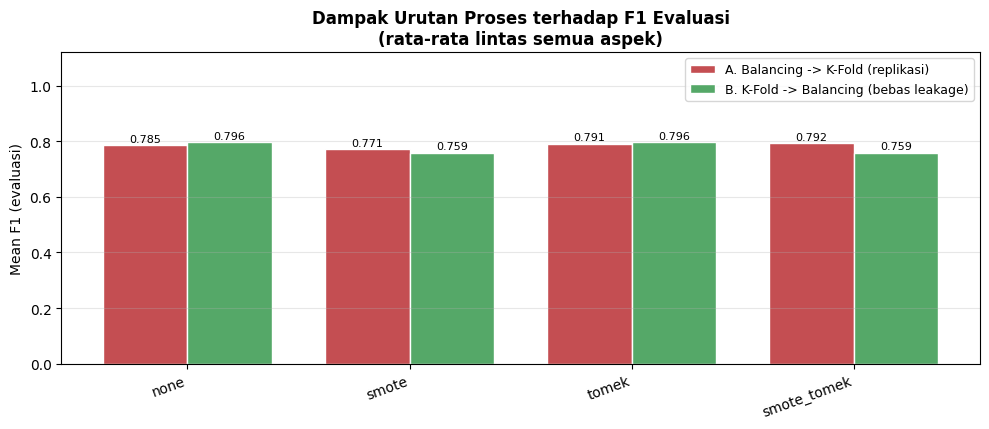

[OK] Grafik disimpan: /content/output_replikasi/perbandingan_protokol.png


In [ ]:
if RUN_PROTOCOL_COMPARISON and len(df_cmp):
    piv = df_cmp.pivot_table(index='Balancing', values=['F1_balancing_lalu_kfold',
                                                       'F1_kfold_lalu_balancing'], aggfunc='mean')
    piv = piv.reindex([b for b in BALANCE_METHODS if b in piv.index])
    xs  = np.arange(len(piv)); w = 0.38

    fig, ax = plt.subplots(figsize=(10, 4.4))
    ax.bar(xs - w/2, piv['F1_balancing_lalu_kfold'], w,
           label='A. Balancing -> K-Fold (replikasi)', color='#C44E52', edgecolor='white')
    ax.bar(xs + w/2, piv['F1_kfold_lalu_balancing'], w,
           label='B. K-Fold -> Balancing (bebas leakage)', color='#55A868', edgecolor='white')
    for i, b in enumerate(piv.index):
        ax.text(i - w/2, piv.loc[b, 'F1_balancing_lalu_kfold'] + 0.012,
                f"{piv.loc[b, 'F1_balancing_lalu_kfold']:.3f}", ha='center', fontsize=8)
        ax.text(i + w/2, piv.loc[b, 'F1_kfold_lalu_balancing'] + 0.012,
                f"{piv.loc[b, 'F1_kfold_lalu_balancing']:.3f}", ha='center', fontsize=8)

    ax.set_xticks(xs); ax.set_xticklabels(piv.index, rotation=20, ha='right')
    ax.set_ylabel('Mean F1 (evaluasi)'); ax.set_ylim(0, 1.12)
    ax.set_title('Dampak Urutan Proses terhadap F1 Evaluasi\n(rata-rata lintas semua aspek)',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    p = OUTPUT_DIR / 'perbandingan_protokol.png'
    plt.savefig(p, dpi=130, bbox_inches='tight')
    plt.show()
    print(f'[OK] Grafik disimpan: {p}')


## 12. Prediksi Satu Kalimat
Prediksi sentimen satu kalimat baru menggunakan model final (dilatih ulang pada seluruh data dengan balancing terbaik tiap aspek).

In [ ]:
# ============================================================
# Ganti teks di bawah untuk prediksi kalimat berbeda
# ============================================================
PREDICT_TEXT = 'Gameplay-nya seru banget tapi grafisnya lag parah di HP kentang'

def preprocess_single(text: str) -> str:
    t = step_case_folding(text)
    t = step_cleansing(t)
    t = step_normalization(t)
    tokens = step_tokenizing(t)
    tokens = step_convert_negasi(tokens)
    tokens = step_stopword_removal(tokens)
    tokens = step_stemming(tokens)
    return ' '.join(tokens)

processed_input = preprocess_single(PREDICT_TEXT)
print(f'Input    : {PREDICT_TEXT}')
print(f'Processed: {processed_input}')

# Deteksi aspek via keyword
tl       = PREDICT_TEXT.lower()
detected = {}
any_main = False
for asp in BASE_ASPECTS:
    kws = [kw for kw in ASPECT_KEYWORDS[asp] if kw in tl]
    detected[asp] = bool(kws)
    if kws:
        any_main = True
detected['others'] = not any_main

print(f'\nDeteksi aspek: {detected}\n')

_cfg_pred = COUNTVEC_CONFIG_BEST if 'COUNTVEC_CONFIG_BEST' in globals() else COUNTVEC_CONFIG

pred_models = {}
print('Melatih ulang model final (seluruh data + balancing terbaik per aspek)...')
for asp in ASPECTS:
    info = all_results.get(asp, {})
    if info.get('skipped') or not info.get('best_scenario'):
        continue
    X_all, y_all = get_aspect_data(df, asp)
    if X_all is None:
        continue
    best_bal = info['best_scenario']

    vec   = build_vectorizer(_cfg_pred)
    X_vec = vec.fit_transform(X_all)
    X_res, y_res = apply_balance(best_bal, X_vec, y_all)
    X_res = clip_nonneg(X_res)
    clf   = MultinomialNB(alpha=float(_cfg_pred.get('alpha', 1.0)))
    clf.fit(X_res, np.asarray(y_res).astype(int))
    pred_models[asp] = {'vec': vec, 'clf': clf, 'bal': best_bal}

print('[OK] Model siap\n')

print(f'{"Aspek":<24s}{"Balancing":<14s}{"Disebut":<10s}{"Sentimen":<16s}{"Prob Negatif":>14s}{"Prob Positif":>14s}')
print('-' * 94)
for asp in ASPECTS:
    bundle = pred_models.get(asp)
    if bundle is None:
        continue
    X_q      = bundle['vec'].transform([processed_input])
    pred     = int(bundle['clf'].predict(X_q)[0])
    proba    = bundle['clf'].predict_proba(X_q)[0]
    prob_map = {int(c): p for c, p in zip(bundle['clf'].classes_, proba)}
    mention  = 'Ya' if detected.get(asp, False) else 'Tidak'
    sent     = SENTIMENT_LABELS[pred] if detected.get(asp, False) else 'Tidak Disebut'
    print(f'{ASPECT_LABELS[asp]:<24s}{bundle["bal"]:<14s}{mention:<10s}{sent:<16s}'
          f'{prob_map.get(-1, 0.0):>14.4f}{prob_map.get(1, 0.0):>14.4f}')


Input    : Gameplay-nya seru banget tapi grafisnya lag parah di HP kentang
Processed: gameplay seru banget grafis lag parah hp kentang

Deteksi aspek: {'gs': True, 'a': False, 'gp': True, 'f': False, 'others': False}

Melatih ulang model final (seluruh data + balancing terbaik per aspek)...
[OK] Model siap

Aspek                   Balancing     Disebut   Sentimen          Prob Negatif  Prob Positif
----------------------------------------------------------------------------------------------
Gameplay & Storyline    none          Ya        Positif                 0.1264        0.8736
Aksesibilitas           smote_tomek   Tidak     Tidak Disebut           0.0482        0.9518
Grafis & Performa       tomek         Ya        Positif                 0.4542        0.5458
Fitur                   smote_tomek   Tidak     Tidak Disebut           0.2270        0.7730
Others                  smote_tomek   Tidak     Tidak Disebut           1.0000        0.0000


## Ringkasan Output

Semua file hasil tersimpan di folder `output_replikasi/`:

| File | Deskripsi |
|---|---|
| `step1_case_folding.csv` … `step7_stemming.csv` | Hasil tiap tahap preprocessing |
| `preprocessing_all_steps.csv` | Semua tahap dalam 1 file |
| `tuning_results.csv` | Hasil grid-search (TrainF1, EvalF1, Gap) |
| `cv_results_per_fold.csv` | **Metrik training & evaluasi tiap fold** |
| `cv_results_summary.csv` | Mean ± Std training & evaluasi per aspek × balancing |
| `results.json` | Seluruh metrik + confusion matrix (JSON) |
| `results_summary.csv` | Ringkasan metrik (CSV) |
| `distribusi_balancing.csv` | Jumlah sampel sebelum/sesudah balancing |
| `perbandingan_protokol.csv` | Selisih F1 antara kedua protokol |
| `train_vs_eval_f1.png` | Bar chart F1 training vs evaluasi |
| `f1_per_fold_train_eval.png` | Kurva F1 per fold |
| `f1_heatmap_train_eval.png` | Heatmap F1 (Aspek × Balancing) |
| `cm_train_eval_{aspek}_{balancing}.png` | CM training vs evaluasi |
| `cm_folds_{aspek}_{balancing}.png` | CM tiap fold |
| `balance_distribution.png` | Grafik distribusi kelas |
| `perbandingan_protokol.png` | Grafik perbandingan protokol |

In [ ]:
print('=== DAFTAR FILE OUTPUT ===')
output_files = sorted(OUTPUT_DIR.glob('*'))
for f in output_files:
    size = f.stat().st_size
    unit = 'KB' if size < 1_000_000 else 'MB'
    size_val = size / 1024 if size < 1_000_000 else size / 1_048_576
    print(f'  {f.name:<48s} {size_val:>7.1f} {unit}')
print(f'\nTotal: {len(output_files)} file di {OUTPUT_DIR}')


=== DAFTAR FILE OUTPUT ===
  balance_distribution.png                           117.6 KB
  cm_a_none.png                                       17.5 KB
  cm_a_ros.png                                        17.2 KB
  cm_a_rus.png                                        17.2 KB
  cm_a_smote.png                                      18.0 KB
  cm_a_smote_tomek.png                                18.4 KB
  cm_a_tomek.png                                      17.4 KB
  cm_f_none.png                                       15.8 KB
  cm_f_ros.png                                        15.6 KB
  cm_f_rus.png                                        15.3 KB
  cm_f_smote.png                                      16.3 KB
  cm_f_smote_tomek.png                                16.6 KB
  cm_f_tomek.png                                      15.7 KB
  cm_folds_a_ros.png                                  68.4 KB
  cm_folds_a_smote_tomek.png                          69.8 KB
  cm_folds_f_ros.png                       